# Apakah riwayat buku membuat rekomendasi lebih personal?

**Pertanyaan utama:** apakah model yang membaca kumpulan buku yang disukai
pengguna memberi rekomendasi lebih baik dibandingkan BPR berbasis ID dan
pembanding popularitas? Eksperimen ini menguji dua objective neural
berbasis riwayat, pembanding klasik yang memakai riwayat sama, serta diagnosis
perubahan rekomendasi ketika riwayat ditukar dengan riwayat pengguna lain.

Alasan pengujian berasal dari hasil sebelumnya. BPR berbasis ID sudah
meningkatkan penemuan target dibanding MLP lama, tetapi daftar rekomendasinya
sangat banyak bertumpang tindih dengan popularitas. Kemiripan tersebut perlu
diperiksa lebih lanjut; ia sendiri belum membuktikan model mengabaikan pengguna.

Notebook ini membaca **tiga JSON bukti tersimpan**. Restart & Run All tidak
melatih model, menghubungi Colab, membuka CSV privat, atau memerlukan GPU dan
TensorFlow. Riwayat keseluruhan tersedia di [notebook 03](03_neural_experiment_history.ipynb),
hasil eksperimen BPR/metadata sebelumnya di [notebook 04](04_neural_ranking_experiments.ipynb).

**Batas evaluasi:** run ini dirancang setelah hasil sebelumnya diketahui.
Assessment internal dipakai ulang, sehingga hasilnya masih pengembangan
adaptif, bukan konfirmasi pada test independen. Pemilihan checkpoint hanya
melalui selection dalam run ini tidak menghapus pemakaian assessment terdahulu.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

root_override = os.environ.get("BOOK_RECOMMENDER_PROJECT_ROOT")
search_root = Path(root_override).resolve() if root_override else Path.cwd().resolve()
ROOT = next(
    (
        path
        for path in (search_root, *search_root.parents)
        if (path / "docs/evidence/neural_colab_history_results.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Buka dari checkout proyek atau set BOOK_RECOMMENDER_PROJECT_ROOT.")
EVIDENCE = ROOT / "docs/evidence"
EVIDENCE_FILES = {
    "results": "neural_colab_history_results.json",
    "manifest": "neural_colab_history_run_manifest.json",
    "diagnosis": "neural_personalization_diagnosis.json",
}
evidence = {
    key: json.loads((EVIDENCE / filename).read_text(encoding="utf-8"))
    for key, filename in EVIDENCE_FILES.items()
}
results, manifest, diagnosis = (evidence[key] for key in ("results", "manifest", "diagnosis"))
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.precision", 8)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
display(
    pd.DataFrame(
        [
            {
                "sumber": filename,
                "SHA256 (newline dinormalisasi)": hashlib.sha256(
                    (EVIDENCE / filename).read_bytes().replace(b"\r\n", b"\n").replace(b"\r", b"\n")
                ).hexdigest(),
            }
            for filename in EVIDENCE_FILES.values()
        ]
    )
)

,sumber,SHA256 (newline dinormalisasi)
0,neural_colab_history_results.json,44a56e611a9841e43e5be75bde8af5ce2bfbb20ee0aaabb4578bd66a058e56b9
1,neural_colab_history_run_manifest.json,ee93d32291c5c1ae4387f1e81eaf8ed0911363f105cc6301a3cb74ce9e48fb13
2,neural_personalization_diagnosis.json,bb939cfd3f0d669fefc3a9413693d13dd81c2e170acd5db899edd64738e163f7


## Hasil utama terlebih dahulu

**Data ini mempunyai sinyal rekomendasi yang berguna, tetapi neural belum
memanfaatkannya secara konsisten.** Pembanding cosine riwayat yang dipilih
melalui selection menemukan **191/1.776** dan **198/1.806** target. Popularitas
menemukan **75/1.776** dan **66/1.806**. Pada dua split ini, pembanding klasik
berbasis hubungan antarkarya memberi hasil terkuat di antara model utama.
Ini bukan hasil evaluasi aplikasi yang sudah dipromosikan atau test baru.

Neural full softmax utama menemukan **109** target pada split 17, meningkat
dari BPR ID lama **72**, tetapi hanya **66** pada split 29 dibanding BPR ID
lama **72**. Neural history-BPR utama menemukan **70** dan **67** target.
Pada cohort positif, semua model neural utama masih memiliki NDCG lebih
rendah daripada cosine terpilih, dengan interval selisih seluruhnya negatif.
Jadi perubahan neural belum memberi peningkatan yang konsisten pada kedua split.

Diagnosis riwayat juga berbeda: softmax utama split 17 turun dari **109** ke
**48** hit ketika diberi riwayat donor, sedangkan split 29 tetap **66** hit.
Ini mendukung kegunaan riwayat asli pada checkpoint split 17, tetapi tidak
membuktikan semua model sudah memakai riwayat secara bermanfaat. Pada split 29,
hit softmax sama dengan popularitas namun posisi target lebih buruk menurut
NDCG cohort positif. Seluruh temuan tetap bersyarat pada assessment pengembangan
yang telah dipakai ulang; belum ada konfirmasi independen.

Tabel ini menampilkan model utama dari selection. “Target ditemukan” berarti
karya relevan yang disembunyikan muncul pada 10 rekomendasi. Hasil seluruh
seed tetap tersedia di bagian rinci; model tidak dipilih ulang menggunakan
assessment. Kelompok pengguna dibedakan menurut jumlah karya positif di fit.

In [2]:
COHORTS = (
    "all_relevant",
    "fit_positive_history",
    "no_fit_positive_history",
    "single_fit_positive",
    "multiple_fit_positive",
)
COMPARISON_COHORTS = ("all_relevant", "fit_positive_history", "multiple_fit_positive")
quick_rows = []
for ranking in results["ranking_results"]:
    chosen = [
        *ranking["primary_models"].items(),
        ("Cosine riwayat", ranking["baseline_name"]),
        ("BPR ID lama", ranking["previous_primary_models"]["bpr_id"]),
        ("Popularitas", "popularity"),
    ]
    for label, name in chosen:
        overall = ranking["metrics"][name]["all_relevant"]
        positive = ranking["metrics"][name]["fit_positive_history"]
        multiple = ranking["metrics"][name]["multiple_fit_positive"]
        quick_rows.append(
            {
                "split": ranking["split_seed"],
                "model utama": label,
                "kandidat": name,
                "target ditemukan (semua)": f"{overall['hits_at_10']}/{overall['users']}",
                "Recall@10 semua (%)": 100 * overall["recall_at_10"],
                "NDCG@10 semua": overall["ndcg_at_10"],
                "NDCG@10 riwayat positif": positive["ndcg_at_10"],
                "target ditemukan (minimal 2 positif)": f"{multiple['hits_at_10']}/{multiple['users']}",
                "NDCG@10 minimal 2 positif": multiple["ndcg_at_10"],
            }
        )
display(pd.DataFrame(quick_rows))

,split,model utama,kandidat,target ditemukan (semua),Recall@10 semua (%),NDCG@10 semua,NDCG@10 riwayat positif,target ditemukan (minimal 2 positif),NDCG@10 minimal 2 positif
0,17,history_bpr,split17_history_bpr_seed7,70/1776,3.94144144,0.02122022,0.02134943,38/902,0.02229762
1,17,history_softmax,split17_history_softmax_seed2026,109/1776,6.13738739,0.03319073,0.03540074,69/902,0.03991468
2,17,Cosine riwayat,split17_itemcos_k50_shrink10,191/1776,10.75450450,0.06752197,0.07569967,131/902,0.09174336
3,17,BPR ID lama,split17_bpr_id_seed42,72/1776,4.05405405,0.02008785,0.02002022,37/902,0.02023052
4,17,Popularitas,popularity,75/1776,4.22297297,0.02096665,0.02105178,41/902,0.02145161
5,29,history_bpr,split29_history_bpr_seed42,67/1806,3.70985604,0.01927901,0.01896956,35/920,0.01917108
6,29,history_softmax,split29_history_softmax_seed42,66/1806,3.65448505,0.01862425,0.01818228,37/920,0.01869540
7,29,Cosine riwayat,split29_itemcos_k50_shrink10,198/1806,10.96345515,0.06615616,0.07533449,127/920,0.08472481
8,29,BPR ID lama,split29_bpr_id_seed2026,72/1806,3.98671096,0.02043383,0.02035811,40/920,0.02100123
9,29,Popularitas,popularity,66/1806,3.65448505,0.02033018,0.02023348,34/920,0.01989515


## Diagnosis sebelum run ini: seberapa mirip BPR ID dengan popularitas?

Diagnosis berikut dihitung sesudah melihat hasil run ketujuh, dari rekomendasi
dan rating fit yang sudah tersimpan. Tidak ada training atau pemilihan ulang
checkpoint. Pada pengguna dengan sedikitnya satu karya positif di fit, buku
peringkat pertama BPR ID sama dengan popularitas pada sekitar **99,74%**
pengguna split 17 dan **97,60%** pengguna split 29. Kedua daftar top 10 rata-rata
memiliki **7,13** dan **6,92** karya yang sama.

Kemiripan ini adalah deskripsi konsentrasi rekomendasi, bukan bukti kausal
bahwa jaringan tidak memakai pengguna. Daftar yang berbeda juga belum tentu
lebih relevan. Karena itu, run baru mengukur kualitas sekaligus sensitivitas
terhadap masukan riwayat, tetap memakai pembanding popularitas.

Post-hoc descriptive diagnosis on reused development assessment; no retraining or checkpoint reselection

,split,BPR utama,cohort,pengguna,top-1 sama dengan popularitas (%),rata-rata karya sama di top-10,rata-rata Jaccard,daftar identik urutan,himpunan karya identik
0,17,split17_bpr_id_seed42,all,1776,99.77477477,7.55799550,0.62150875,263,263
1,17,split17_bpr_id_seed42,positive,1513,99.73562459,7.13350958,0.55571681,0,0
2,17,split17_bpr_id_seed42,at_least_two_positive,902,99.55654102,7.19401330,0.56356762,0,0
3,29,split29_bpr_id_seed2026,all,1806,98.00664452,7.44130676,0.60947653,304,304
4,29,split29_bpr_id_seed2026,positive,1502,97.60319574,6.92343542,0.53043583,0,0
5,29,split29_bpr_id_seed2026,at_least_two_positive,920,96.52173913,6.88913043,0.52681196,0,0


,split,jumlah karya positif,pengguna,model,hits,recall,ndcg
0,17,0,263,split17_mse_id_seed7,10,0.03802281,0.02047690
1,17,0,263,split17_bpr_id_seed42,10,0.03802281,0.02047690
2,17,0,263,split17_bpr_metadata_seed7,10,0.03802281,0.02047690
3,17,0,263,split17_mlp_seed42,3,0.01140684,0.00755565
4,17,0,263,popularity,10,0.03802281,0.02047690
5,17,1,611,split17_mse_id_seed7,16,0.02618658,0.01532722
6,17,1,611,split17_bpr_id_seed42,25,0.04091653,0.01970976
7,17,1,611,split17_bpr_metadata_seed7,23,0.03764321,0.01943700
8,17,1,611,split17_mlp_seed42,6,0.00981997,0.00409407
9,17,1,611,popularity,24,0.03927987,0.02046152


,split,kelompok/model,unique_works,top10_global_exposure_fraction,top1_exposure_fraction,unique_ordered_lists,unique_item_sets
0,17,all_split17_bpr_id_seed42,18,0.93873874,0.09864865,98,59
1,17,all_popularity,17,0.98141892,0.09864865,45,45
2,17,positive_split17_bpr_id_seed42,17,0.98023794,0.09900859,92,53
3,17,positive_popularity,17,0.97865169,0.09841375,45,45
4,17,at_least_two_positive_split17_bpr_id_seed42,17,0.97095344,0.09844789,90,53
5,17,at_least_two_positive_popularity,17,0.96873614,0.09767184,44,44
6,29,all_split29_bpr_id_seed2026,17,0.93089701,0.09889258,77,70
7,29,all_popularity,17,0.98222591,0.09894795,57,57
8,29,positive_split29_bpr_id_seed2026,17,0.97789614,0.09880160,73,66
9,29,positive_popularity,17,0.97902796,0.09880160,57,57


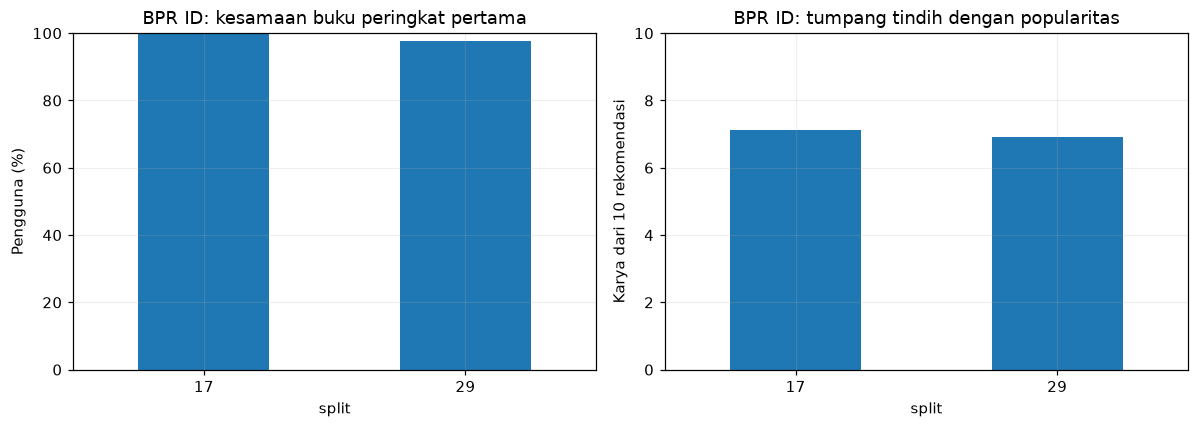

In [3]:
diagnosis_rows, diagnosis_bucket_rows, exposure_rows = [], [], []
for split in diagnosis["splits"]:
    for cohort, metrics in split["overlap"].items():
        diagnosis_rows.append(
            {
                "split": split["split_seed"],
                "BPR utama": split["primary_bpr"],
                "cohort": cohort,
                "pengguna": metrics["users"],
                "top-1 sama dengan popularitas (%)": 100 * metrics["same_top1"] / metrics["users"],
                "rata-rata karya sama di top-10": metrics["mean_common_top10"],
                "rata-rata Jaccard": metrics["mean_jaccard"],
                "daftar identik urutan": metrics["exact_ordered_lists"],
                "himpunan karya identik": metrics["identical_item_sets"],
            }
        )
    for bucket in split["metrics_by_bucket"]:
        for name, metrics in bucket["models"].items():
            diagnosis_bucket_rows.append(
                {
                    "split": split["split_seed"],
                    "jumlah karya positif": bucket["positive_fit_works"],
                    "pengguna": bucket["users"],
                    "model": name,
                    **metrics,
                }
            )
    for group, metrics in split["exposure"].items():
        exposure_rows.append({"split": split["split_seed"], "kelompok/model": group, **metrics})
diagnosis_table = pd.DataFrame(diagnosis_rows)
display(Markdown(diagnosis["scope"]))
display(diagnosis_table)
display(pd.DataFrame(diagnosis_bucket_rows))
display(pd.DataFrame(exposure_rows))
positive_diagnosis = diagnosis_table[diagnosis_table["cohort"] == "positive"].set_index("split")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positive_diagnosis["top-1 sama dengan popularitas (%)"].plot.bar(ax=axes[0], rot=0)
positive_diagnosis["rata-rata karya sama di top-10"].plot.bar(ax=axes[1], rot=0)
axes[0].set(ylim=(0, 100), ylabel="Pengguna (%)", title="BPR ID: kesamaan buku peringkat pertama")
axes[1].set(
    ylim=(0, 10),
    ylabel="Karya dari 10 rekomendasi",
    title="BPR ID: tumpang tindih dengan popularitas",
)
plt.tight_layout()
plt.show()

## Apa yang berubah pada run ini?

Model baru membentuk representasi pengguna dari **himpunan karya positif**
pada fit: karya dengan salah satu rating edisinya minimal 8. Embedding karya
dalam riwayat dijumlahkan, dibagi akar jumlah karya, lalu melalui Dense 64
dengan tanh dan Dense 32. Representasi pengguna tersebut dibandingkan dengan
embedding keluaran setiap kandidat karya; skor juga mempunyai bias karya.
Embedding masukan riwayat dan embedding keluaran kandidat adalah parameter
terpisah. Identitas pengguna tidak menjadi embedding yang dilatih pada model ini.

Riwayat adalah **himpunan tanpa urutan waktu**. Tidak ada klaim bahwa jaringan
mempelajari urutan pembacaan atau memprediksi buku berikutnya secara temporal.
Gagasan memakai embedding riwayat sebagai masukan juga muncul pada contoh
[retrieval TensorFlow Recommenders](https://www.tensorflow.org/recommenders/examples/sequential_retrieval),
tetapi contoh itu menggunakan urutan dan GRU. Implementasi proyek ini bukan
reproduksi model sekuensial tersebut.

Dua objective memakai arsitektur, inisialisasi berpasangan, dan contoh target
training yang sama:

| Kelompok | Sasaran latihan |
|---|---|
| `history_bpr` | Menaikkan skor target positif terhadap satu kandidat pembanding yang disampling |
| `history_softmax` | Menaikkan probabilitas target terhadap seluruh kandidat yang diizinkan dalam katalog |

BPR menggunakan `softplus(skor pembanding - skor target)`. Full softmax memakai
cross-entropy target pada skor katalog. Keduanya mengejar ranking melalui
bentuk perbandingan berbeda; loss dan jumlah kandidat pembandingnya tidak
berada pada skala yang dapat dibandingkan langsung.
Pemakaian likelihood multinomial untuk rekomendasi juga dibahas dalam
[Liang dkk., Variational Autoencoders for Collaborative Filtering](https://arxiv.org/abs/1802.05814).
Model proyek ini memakai encoder deterministik; tidak memiliki encoder
variational atau loss KL dan bukan reproduksi VAE dari paper tersebut.

Perbandingan dengan BPR ID lama mengubah representasi **serta pengguna/contoh
training yang memenuhi syarat dan definisi regularisasi**. Selisih hasilnya
tidak mengisolasi manfaat encoder riwayat saja. Perbandingan `history_bpr`
dengan `history_softmax` lebih terkontrol untuk objective karena memakai
arsitektur, contoh target, konteks, dan inisialisasi yang sama.

## Mencegah target masuk ke riwayat training

Untuk setiap target positif pada fit, **karya target dikeluarkan dari riwayat
sebelum pooling**. Pengguna training harus mempunyai sedikitnya dua karya
positif agar masih ada konteks setelah satu target dikeluarkan. Satu pengguna
dapat menyumbang beberapa contoh training; satu contoh adalah satu karya
target dan riwayat positif lainnya. Ini bukan pembuatan split assessment baru.
Pengguna dengan lebih banyak karya positif menyumbang lebih banyak target;
pembobotan training dilakukan per contoh, bukan sama rata per pengguna.

Ketika selection/assessment, model memakai seluruh riwayat positif fit.
Pengguna dengan satu karya positif tetap bisa menerima skor neural, walaupun
pengguna dengan satu positif tidak menyumbang target latihan berbasis riwayat.
Pengguna tanpa positif memakai fallback popularitas. Semua karya yang ada di
fit pengguna, termasuk yang ratingnya rendah, dikeluarkan dari rekomendasi.

Kandidat negatif BPR disampling dari karya yang tidak ada dalam seluruh fit
pengguna. Softmax menutup skor semua karya fit selain target training;
target dibuka kembali sebagai label yang sah. Dengan demikian, karya positif
lain dalam riwayat tidak dihukum sebagai alternatif negatif pada contoh itu.
Preferensi terhadap kandidat yang belum diamati tetap tidak diketahui:
**belum tercatat bukan berarti tidak disukai**. Label selection/assessment
tidak dipakai untuk menyusun contoh training atau memilih negatif.

In [4]:
display(pd.DataFrame(results["dataset"]["training_work_summaries"]))
training_bucket_rows = []
for split in diagnosis["splits"]:
    training_bucket_rows.append(
        {
            "split": split["split_seed"],
            **{
                f"pengguna fit {bucket} positif": count
                for bucket, count in split["train_users_by_positive_bucket"].items()
            },
            "pengguna minimal 2 positif": split["train_eligible_leave_one_positive_out_users"],
            "contoh leave-one-positive-out": split["train_eligible_leave_one_positive_out_pairs"],
        }
    )
display(pd.DataFrame(training_bucket_rows))
assert results["dataset"]["reused_prior_assessment"]
assert not results["original_test_used"]
assert not results["original_validation_used"]
assert not results["model_promotion_to_application"]

,split_seed,fit_user_work_pairs,fit_positive_user_work_pairs,training_examples,fit_users,fit_works,fit_positive_users,fit_no_positive_users,fit_single_positive_users,fit_multiple_positive_users,trained_positive_target_works,positive_target_work_coverage,max_positive_history,selection_relevant_users,selection_fit_positive_users,selection_no_fit_positive_users,history_shuffle_changed_users,metadata_used_by_network
0,17,105498,65839,61820,15312,4364,12836,2476,4019,8817,4357,0.99839597,1004,1795,1513,282,12836,False
1,29,105498,65836,61923,15312,4364,12780,2532,3913,8867,4359,0.99885426,1004,1768,1471,297,12780,False


,split,pengguna fit 2-4 positif,pengguna fit 1 positif,pengguna fit 5+ positif,pengguna fit 0 positif,pengguna minimal 2 positif,contoh leave-one-positive-out
0,17,5578,4019,3239,2476,8817,61820
1,29,5610,3913,3257,2532,8867,61923


## Pembanding klasik yang memakai riwayat positif sama

Pembanding klasik menghitung cosine antar-karya dari interaksi positif fit.
Skor kandidat dikumpulkan dari kemiripannya dengan karya positif dalam
riwayat. Grid membandingkan 50/200 tetangga dan shrinkage 0/10, sehingga ada
empat konfigurasi per split, delapan catatan konfigurasi klasik keseluruhan.
Shrinkage mengurangi kemiripan yang didukung sedikit pengguna bersama:
cosine dikalikan `jumlah pengguna bersama / (jumlah pengguna bersama + shrinkage)`.
Jadi konfigurasi dengan shrinkage 10 bukan cosine tanpa pembobotan tambahan.
Checkpoint neural dan konfigurasi klasik sama-sama dipilih melalui NDCG@10
selection, dengan Recall@10 sebagai pemecah seri.

Pembanding ini membantu membedakan manfaat membaca riwayat dengan manfaat
jaringan neural. Ia tidak dilatih melalui backpropagation dan tidak dihitung
sebagai training neural baru. Popularitas dan hasil neural terdahulu juga
dipakai sebagai benchmark dengan pilihan model historis tetap.
Pada skor cosine yang persis sama, popularitas fit lalu urutan leksikal karya
menjadi pemecah seri; pada neural, seri diselesaikan lewat urutan leksikal.
Ini kebijakan yang ditetapkan sebelum penilaian, bukan perbedaan yang
disembunyikan. Cosine ini berbasis interaksi positif karya kanonik, berbeda
dari adjusted-cosine rating ISBN pada aplikasi awal.

In [5]:
baselines = results["baseline_grid_results"]
baseline_rows = []
for baseline in baselines:
    baseline_rows.append(
        {
            "kandidat": baseline["name"],
            "split": baseline["split_seed"],
            "tetangga k": baseline["k"],
            "shrinkage": baseline["shrink"],
            "status": baseline["status"],
            "terpilih dari selection": baseline["selected"],
            "selection NDCG@10": baseline["selection"]["all_relevant"]["ndcg_at_10"],
            "selection Recall@10": baseline["selection"]["all_relevant"]["recall_at_10"],
            "selection NDCG@10 minimal 2 positif": baseline["selection"]["multiple_fit_positive"][
                "ndcg_at_10"
            ],
            "kemiripan bukan nol": baseline["similarity_nonzero"],
            "save/load terverifikasi": baseline["model_roundtrip_verified"],
            "durasi (detik)": baseline["seconds"],
        }
    )
display(pd.DataFrame(baseline_rows))

,kandidat,split,tetangga k,shrinkage,status,terpilih dari selection,selection NDCG@10,selection Recall@10,selection NDCG@10 minimal 2 positif,kemiripan bukan nol,save/load terverifikasi,durasi (detik)
0,split17_itemcos_k50_shrink0,17,50,0.0,completed,False,0.04808295,0.07520891,0.06398050,208715,True,1.47037520
1,split17_itemcos_k50_shrink10,17,50,10.0,completed,True,0.06533698,0.10250696,0.09190444,208715,True,1.52695527
2,split17_itemcos_k200_shrink0,17,200,0.0,completed,False,0.04772747,0.07353760,0.06328993,697562,True,2.09371673
3,split17_itemcos_k200_shrink10,17,200,10.0,completed,False,0.06504613,0.10083565,0.09133942,697562,True,2.07287789
4,split29_itemcos_k50_shrink0,29,50,0.0,completed,False,0.05748058,0.08427602,0.07547014,208922,True,1.52918178
5,split29_itemcos_k50_shrink10,29,50,10.0,completed,True,0.07476179,0.11595023,0.10248194,208922,True,1.46539122
6,split29_itemcos_k200_shrink0,29,200,0.0,completed,False,0.05690949,0.08314480,0.07435199,697595,True,2.15826002
7,split29_itemcos_k200_shrink10,29,200,10.0,completed,False,0.07443644,0.11481900,0.10184495,697595,True,2.10152162


## Protokol dan seluruh konfigurasi

Dua split (17 dan 29), tiga seed (42, 2026, 7), dan dua objective menghasilkan
12 rencana training neural. Adam memakai learning rate 0,001, batch 1.024,
maksimal 20 epoch, dan patience 4. Regularisasi `1e-5 × mean(parameter²)`
diterapkan pada seluruh parameter trainable. Definisi ini berbeda dari
regularisasi sampled-pair pada run sebelumnya; angka lambda saja tidak
menunjukkan kekuatan penyusutan yang sama.

Semua kandidat harus selesai dan seluruh model terpilih dikunci melalui
sidik hash sebelum assessment run ini dibuka. Seluruh seed dilaporkan;
penilaian pada assessment tidak memilih ulang model utama.

In [6]:
display(
    pd.DataFrame(
        [
            {"pengaturan": key, "nilai": value}
            for key, value in results["configuration"].items()
            if key != "candidates"
        ]
    )
)
display(
    pd.DataFrame(
        [
            {
                "status run": results["status"],
                "selesai (Asia/Jakarta)": pd.Timestamp(results["completed_utc"])
                .tz_convert("Asia/Jakarta")
                .isoformat(),
                "seluruh kandidat selesai": results["all_candidates_completed"],
                "assessment dilakukan": results["assessment_performed"],
                "durasi eksperimen (detik)": results["total_seconds"],
                "epoch neural": results["training"]["total_neural_epochs"],
            }
        ]
    )
)
candidates = results["candidate_validation_results"]
candidate_by_name = {candidate["name"]: candidate for candidate in candidates}
assert len(candidate_by_name) == len(candidates)
candidate_rows = []
for candidate in candidates:
    candidate_rows.append(
        {
            "kandidat": candidate["name"],
            "split": candidate["split_seed"],
            "kelompok": candidate["arm"],
            "seed": candidate["initialization_seed"],
            "status": candidate["status"],
            "epoch selesai": candidate["epochs_completed"],
            "epoch terbaik": candidate["best_epoch"],
            "checkpoint terbaik di batas epoch": candidate["best_at_epoch_cap"],
            "contoh per epoch": candidate["training_examples_per_epoch"],
            "update Adam": candidate["optimizer_iterations"],
            "selection NDCG@10": candidate["selection"]["all_relevant"]["ndcg_at_10"],
            "selection Recall@10": candidate["selection"]["all_relevant"]["recall_at_10"],
            "selection NDCG@10 minimal 2 positif": candidate["selection"]["multiple_fit_positive"][
                "ndcg_at_10"
            ],
            "save/load terverifikasi": candidate["model_roundtrip_verified"],
            "SHA256 parameter awal": candidate["initial_trainable_sha256"],
        }
    )
candidate_table = pd.DataFrame(candidate_rows)
display(candidate_table)
assert candidate_table.groupby(["split", "seed"])["SHA256 parameter awal"].nunique().eq(1).all()
selection_rows = []
for split in results["primary_selection"]:
    assert split["selection_only"]
    for arm in split["arms"]:
        selection_rows.append(
            {
                "split": split["split_seed"],
                "kelompok": arm["arm"],
                "model utama": arm["primary_candidate"],
                "jumlah seed": arm["n_seeds"],
                "selection NDCG mean": arm["selection_ndcg_at_10_mean"],
                "selection NDCG SD": arm["selection_ndcg_at_10_std"],
                "cosine terpilih": split["baseline_candidate"],
            }
        )
display(pd.DataFrame(selection_rows))
display(
    Markdown(
        "Hash bobot awal cocok pada kedua objective untuk setiap pasangan split/seed. "
        "RNG urutan contoh dipisahkan dari RNG negatif BPR sehingga urutan contoh "
        "per epoch dapat dipasangkan. Patience dapat menghasilkan jumlah epoch "
        "akhir berbeda. Checkpoint terbaik tepat pada batas epoch belum membuktikan konvergensi."
    )
)

,pengaturan,nilai
0,started_utc,2026-10-14T09:57:00.319003+00:00
1,split_seeds,"[17, 29]"
2,training_seeds,"[42, 2026, 7]"
3,arms,"[history_bpr, history_softmax]"
4,embedding_size,32
5,architecture,Untied input/output item embeddings; sum positive history / sqrt(count) -> Dense64 tanh -> Dense32; dot ou...
6,paired_initialization,Same seed gives identical trainable values across BPR and full softmax
7,random_streams,"Minibatch order uses seed; BPR negatives use seed+10000 independently, preserving identical epoch orders a..."
8,context,"Fit positive works (any edition rated>=8), deduplicated; remove target before encoding during training; al..."
9,training_examples,One positive user/work target for users with at least two fit-positive works; per-example weighting


,status run,selesai (Asia/Jakarta),seluruh kandidat selesai,assessment dilakukan,durasi eksperimen (detik),epoch neural
0,completed,2026-10-14T17:06:12.891965+07:00,True,True,552.81446943,136


,kandidat,split,kelompok,seed,status,epoch selesai,epoch terbaik,checkpoint terbaik di batas epoch,contoh per epoch,update Adam,selection NDCG@10,selection Recall@10,selection NDCG@10 minimal 2 positif,save/load terverifikasi,SHA256 parameter awal
0,split17_history_bpr_seed42,17,history_bpr,42,completed,10,6,False,61820,610,0.01717944,0.03509749,0.01284507,True,bd1c46068153e394a4f6dc72426ff46048e40393d7f9113182a2d7d4e187e712
1,split17_history_softmax_seed42,17,history_softmax,42,completed,8,4,False,61820,488,0.01690380,0.03064067,0.01321628,True,bd1c46068153e394a4f6dc72426ff46048e40393d7f9113182a2d7d4e187e712
2,split17_history_bpr_seed2026,17,history_bpr,2026,completed,7,3,False,61820,427,0.01792523,0.03509749,0.01641740,True,ad7e0832736e8d1189f6862a351ac865b6c972c8cdf8b97292ab35aaef100906
3,split17_history_softmax_seed2026,17,history_softmax,2026,completed,20,19,False,61820,1220,0.02822267,0.05738162,0.03488067,True,ad7e0832736e8d1189f6862a351ac865b6c972c8cdf8b97292ab35aaef100906
4,split17_history_bpr_seed7,17,history_bpr,7,completed,10,6,False,61820,610,0.01940874,0.03844011,0.01450012,True,6d222ee78a354f816345420bcd26d0164d187cb8b6b71ad9c952d40ca780e588
5,split17_history_softmax_seed7,17,history_softmax,7,completed,20,20,True,61820,1220,0.02667434,0.04958217,0.03187484,True,6d222ee78a354f816345420bcd26d0164d187cb8b6b71ad9c952d40ca780e588
6,split29_history_bpr_seed42,29,history_bpr,42,completed,20,16,False,61923,1220,0.02235963,0.04185520,0.02201152,True,bd1c46068153e394a4f6dc72426ff46048e40393d7f9113182a2d7d4e187e712
7,split29_history_softmax_seed42,29,history_softmax,42,completed,6,2,False,61923,366,0.02008502,0.03733032,0.02031417,True,bd1c46068153e394a4f6dc72426ff46048e40393d7f9113182a2d7d4e187e712
8,split29_history_bpr_seed2026,29,history_bpr,2026,completed,12,8,False,61923,732,0.02012142,0.03676471,0.01895983,True,ad7e0832736e8d1189f6862a351ac865b6c972c8cdf8b97292ab35aaef100906
9,split29_history_softmax_seed2026,29,history_softmax,2026,completed,7,3,False,61923,427,0.01957438,0.03506787,0.01939684,True,ad7e0832736e8d1189f6862a351ac865b6c972c8cdf8b97292ab35aaef100906


,split,kelompok,model utama,jumlah seed,selection NDCG mean,selection NDCG SD,cosine terpilih
0,17,history_bpr,split17_history_bpr_seed7,3,0.01817114,0.00113481,split17_itemcos_k50_shrink10
1,17,history_softmax,split17_history_softmax_seed2026,3,0.02393360,0.00613701,split17_itemcos_k50_shrink10
2,29,history_bpr,split29_history_bpr_seed42,3,0.02149649,0.00120372,split29_itemcos_k50_shrink10
3,29,history_softmax,split29_history_softmax_seed42,3,0.01985689,0.00025963,split29_itemcos_k50_shrink10


Hash bobot awal cocok pada kedua objective untuk setiap pasangan split/seed. RNG urutan contoh dipisahkan dari RNG negatif BPR sehingga urutan contoh per epoch dapat dipasangkan. Patience dapat menghasilkan jumlah epoch akhir berbeda. Checkpoint terbaik tepat pada batas epoch belum membuktikan konvergensi.

## Semua epoch, checkpoint, dan perubahan bobot

Checkpoint terbaik ditentukan oleh NDCG selection; bukan loss train terkecil.
Penurunan loss hanya menyatakan target latihan membaik. Gradien dan perubahan
parameter memperlihatkan embedding, forward propagation, loss, backpropagation,
dan Adam bekerja; manfaat rekomendasi tetap diukur dengan metrik holdout.

,candidate,arm,split_seed,training_seed,epoch,train_data_loss,train_total_loss,reg_loss,gradient_norm,training_examples,optimizer_iterations,selection_ndcg_at_10,selection_recall_at_10,selection_fit_positive_ndcg_at_10,selection_multiple_positive_ndcg_at_10,selected_checkpoint
0,split17_history_bpr_seed42,history_bpr,17,42,1,0.68792491,0.68792491,0.00000003,0.02493831,61820,61,0.01460883,0.03175487,0.01419964,0.01474830,False
1,split17_history_bpr_seed42,history_bpr,17,42,2,0.59479139,0.59479144,0.00000003,0.06676135,61820,122,0.01510782,0.03064067,0.01479162,0.01186710,False
2,split17_history_bpr_seed42,history_bpr,17,42,3,0.52280828,0.52280834,0.00000004,0.08866360,61820,183,0.01645123,0.03008357,0.01638543,0.01277117,False
3,split17_history_bpr_seed42,history_bpr,17,42,4,0.51215076,0.51215081,0.00000004,0.08516077,61820,244,0.01635914,0.03008357,0.01627617,0.01258200,False
4,split17_history_bpr_seed42,history_bpr,17,42,5,0.50664152,0.50664158,0.00000005,0.08363401,61820,305,0.01694648,0.03175487,0.01697298,0.01374547,False
5,split17_history_bpr_seed42,history_bpr,17,42,6,0.50080738,0.50080744,0.00000005,0.08338843,61820,366,0.01717944,0.03509749,0.01724937,0.01284507,True
6,split17_history_bpr_seed42,history_bpr,17,42,7,0.49853457,0.49853463,0.00000005,0.08186807,61820,427,0.01714640,0.03398329,0.01721016,0.01239508,False
7,split17_history_bpr_seed42,history_bpr,17,42,8,0.49444740,0.49444746,0.00000005,0.08112663,61820,488,0.01623492,0.03119777,0.01612881,0.01219246,False
8,split17_history_bpr_seed42,history_bpr,17,42,9,0.49341343,0.49341349,0.00000005,0.07988338,61820,549,0.01623140,0.03119777,0.01612462,0.01356549,False
9,split17_history_bpr_seed42,history_bpr,17,42,10,0.49006073,0.49006079,0.00000006,0.08046873,61820,610,0.01648158,0.03175487,0.01642144,0.01381680,False


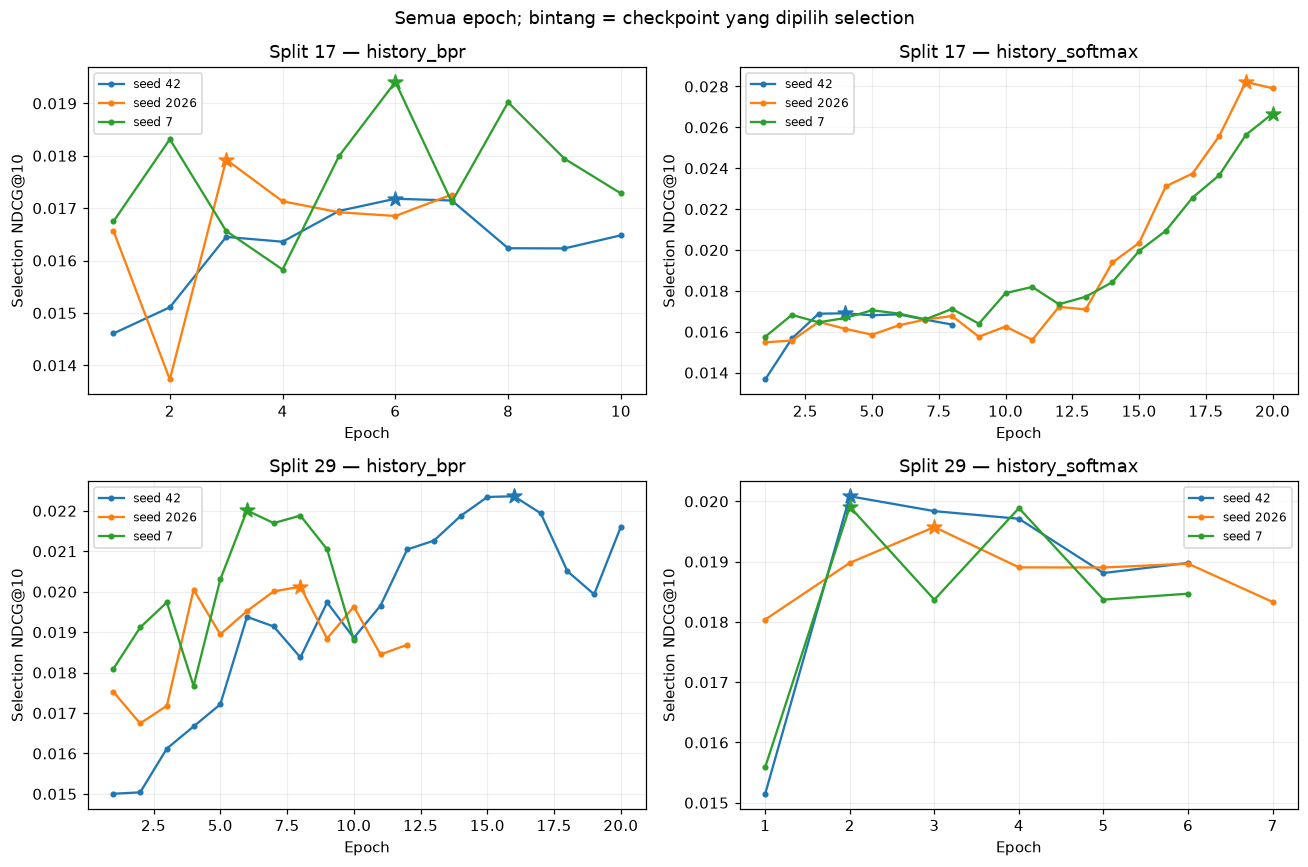

In [7]:
epoch_rows = []
for candidate in candidates:
    assert len(candidate["history"]) == candidate["epochs_completed"]
    for epoch in candidate["history"]:
        epoch_rows.append(
            {
                "candidate": candidate["name"],
                "arm": candidate["arm"],
                "split_seed": candidate["split_seed"],
                "training_seed": candidate["initialization_seed"],
                **epoch,
                "selected_checkpoint": epoch["epoch"] == candidate["best_epoch"],
            }
        )
epochs = pd.DataFrame(epoch_rows)
assert len(epochs) == results["training"]["total_neural_epochs"]
display(epochs)
arms = ["history_bpr", "history_softmax"]
split_seeds = sorted({candidate["split_seed"] for candidate in candidates})
training_seeds = [42, 2026, 7]
seed_colors = {42: "tab:blue", 2026: "tab:orange", 7: "tab:green"}
fig, axes = plt.subplots(len(split_seeds), len(arms), figsize=(12, 8), squeeze=False)
for row_index, split_seed in enumerate(split_seeds):
    for column_index, arm in enumerate(arms):
        ax = axes[row_index, column_index]
        for training_seed in training_seeds:
            group = epochs[
                (epochs["split_seed"] == split_seed)
                & (epochs["arm"] == arm)
                & (epochs["training_seed"] == training_seed)
            ].sort_values("epoch")
            ax.plot(
                group["epoch"],
                group["selection_ndcg_at_10"],
                marker=".",
                label=f"seed {training_seed}",
                color=seed_colors[training_seed],
            )
            best = group[group["selected_checkpoint"]]
            ax.scatter(
                best["epoch"],
                best["selection_ndcg_at_10"],
                marker="*",
                s=100,
                color=seed_colors[training_seed],
            )
        ax.set(title=f"Split {split_seed} — {arm}", xlabel="Epoch", ylabel="Selection NDCG@10")
        ax.legend(fontsize=8)
fig.suptitle("Semua epoch; bintang = checkpoint yang dipilih selection")
plt.tight_layout()
plt.show()

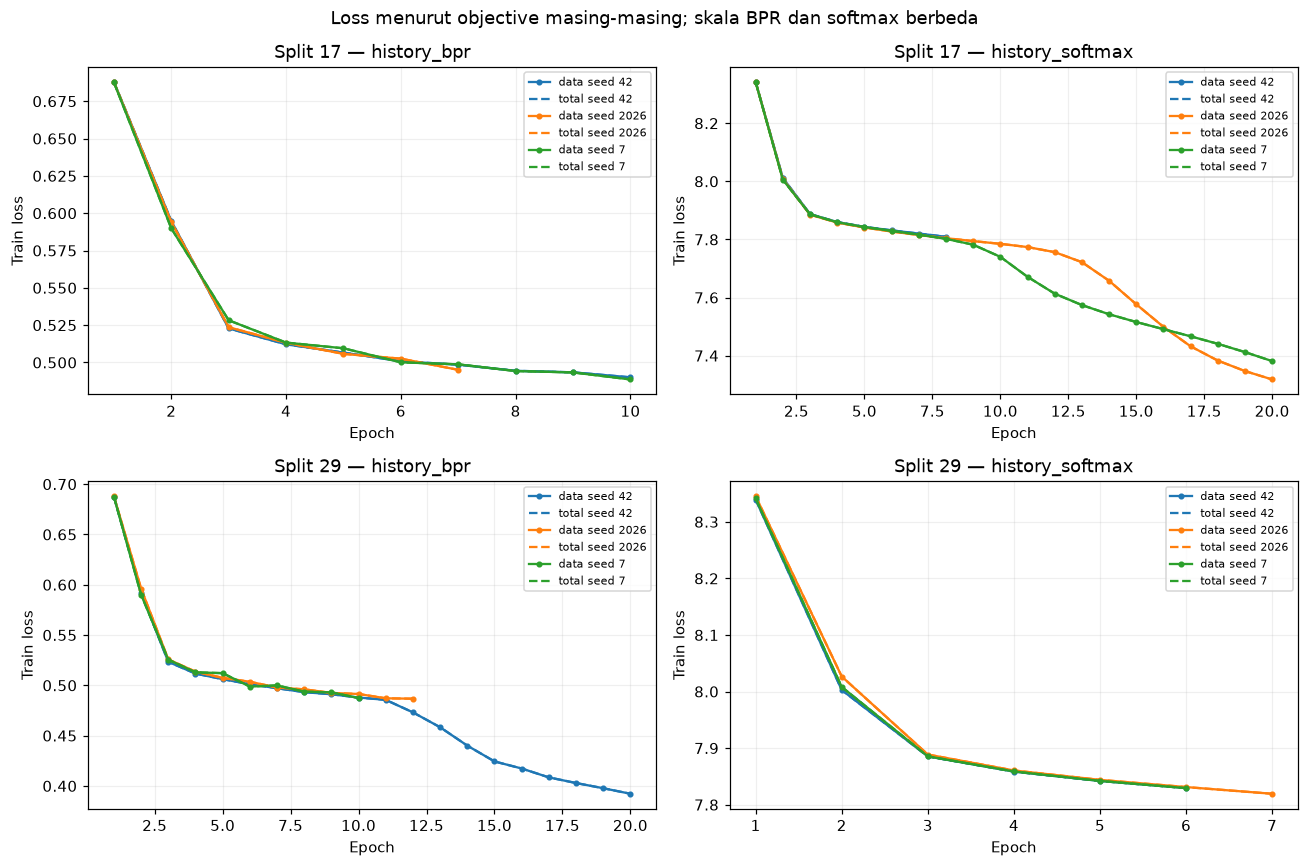

In [8]:
fig, axes = plt.subplots(len(split_seeds), len(arms), figsize=(12, 8), squeeze=False)
for row_index, split_seed in enumerate(split_seeds):
    for column_index, arm in enumerate(arms):
        ax = axes[row_index, column_index]
        for training_seed in training_seeds:
            group = epochs[
                (epochs["split_seed"] == split_seed)
                & (epochs["arm"] == arm)
                & (epochs["training_seed"] == training_seed)
            ].sort_values("epoch")
            ax.plot(
                group["epoch"],
                group["train_data_loss"],
                marker=".",
                label=f"data seed {training_seed}",
                color=seed_colors[training_seed],
            )
            ax.plot(
                group["epoch"],
                group["train_total_loss"],
                linestyle="--",
                label=f"total seed {training_seed}",
                color=seed_colors[training_seed],
            )
        ax.set(title=f"Split {split_seed} — {arm}", xlabel="Epoch", ylabel="Train loss")
        ax.legend(fontsize=7)
fig.suptitle("Loss menurut objective masing-masing; skala BPR dan softmax berbeda")
plt.tight_layout()
plt.show()

In [9]:
trace_rows, update_rows, example_rows, vector_rows = [], [], [], []
for candidate in candidates:
    trace = candidate["first_step_trace"]
    trace_rows.append(
        {
            "kandidat": candidate["name"],
            "objective": trace["objective"],
            "batch": trace["batch_size"],
            "iterasi Adam setelah update": trace["optimizer_iterations"],
            **trace["loss_before_update"],
        }
    )
    for variable, value in trace["variable_update_norms"].items():
        update_rows.append(
            {
                "kandidat": candidate["name"],
                "parameter": variable,
                "norma perubahan sesudah Adam": value,
            }
        )
    for index, (before, after, count, vector) in enumerate(
        zip(
            trace["raw_positive_scores_before"],
            trace["raw_positive_scores_after"],
            trace["context_positive_counts_after_target_removal"],
            trace["context_pooled_vectors_before"],
        ),
        start=1,
    ):
        assert count >= 1, "Target training harus menyisakan riwayat konteks."
        negative = trace["raw_negative_scores_before"]
        example_rows.append(
            {
                "kandidat": candidate["name"],
                "contoh": index,
                "karya konteks sesudah target dikeluarkan": count,
                "norma vektor konteks": sum(value * value for value in vector) ** 0.5,
                "skor target sebelum": before,
                "skor target sesudah": after,
                "skor negatif BPR sebelum": negative[index - 1] if negative else None,
            }
        )
        vector_rows.append(
            {
                "kandidat": candidate["name"],
                "contoh": index,
                **{
                    f"dimensi {dimension}": value for dimension, value in enumerate(vector, start=1)
                },
            }
        )
display(pd.DataFrame(trace_rows))
display(pd.DataFrame(update_rows))
display(pd.DataFrame(example_rows).fillna("softmax memakai seluruh kandidat yang diizinkan"))
display(pd.DataFrame(vector_rows))
display(
    Markdown(
        "Vektor adalah hasil pooling embedding riwayat **sebelum Dense**, setelah target "
        "dikeluarkan. Norma gradien tercatat sebelum Adam; norma perubahan parameter "
        "tercatat sesudah Adam dan bukan gradien per parameter. Bukti mekanisme ini "
        "harus dibaca bersama tes pengecualian target dan kualitas selection/assessment."
    )
)

,kandidat,objective,batch,iterasi Adam setelah update,loss,data_loss,regularization_loss,gradient_norm
0,split17_history_bpr_seed42,bpr,1024,1,0.69311094,0.69311094,0.00000003,0.02480102
1,split17_history_softmax_seed42,softmax,1024,1,8.36683273,8.36683273,0.00000003,0.03841383
2,split17_history_bpr_seed2026,bpr,1024,1,0.69312650,0.69312650,0.00000003,0.02489745
3,split17_history_softmax_seed2026,softmax,1024,1,8.36380768,8.36380768,0.00000003,0.03877349
4,split17_history_bpr_seed7,bpr,1024,1,0.69313157,0.69313157,0.00000003,0.02481123
5,split17_history_softmax_seed7,softmax,1024,1,8.36780643,8.36780643,0.00000003,0.03719036
6,split29_history_bpr_seed42,bpr,1024,1,0.69309384,0.69309384,0.00000003,0.02441626
7,split29_history_softmax_seed42,softmax,1024,1,8.36708641,8.36708641,0.00000003,0.03720966
8,split29_history_bpr_seed2026,bpr,1024,1,0.69315249,0.69315249,0.00000003,0.02428092
9,split29_history_softmax_seed2026,softmax,1024,1,8.36396980,8.36396980,0.00000003,0.03749870


,kandidat,parameter,norma perubahan sesudah Adam
0,split17_history_bpr_seed42,history_ranking_encoder/work_bias,0.03795269
1,split17_history_bpr_seed42,history_ranking_encoder/context_embedding/embeddings,0.12682110
2,split17_history_bpr_seed42,history_ranking_encoder/output_embedding/embeddings,0.11174354
3,split17_history_bpr_seed42,history_ranking_encoder/history_hidden/kernel,0.02794110
4,split17_history_bpr_seed42,history_ranking_encoder/history_hidden/bias,0.00757089
5,split17_history_bpr_seed42,history_ranking_encoder/history_output/kernel,0.02808102
6,split17_history_bpr_seed42,history_ranking_encoder/history_output/bias,0.00545101
7,split17_history_softmax_seed42,history_ranking_encoder/work_bias,0.06528401
8,split17_history_softmax_seed42,history_ranking_encoder/context_embedding/embeddings,0.14897418
9,split17_history_softmax_seed42,history_ranking_encoder/output_embedding/embeddings,0.10405149


,kandidat,contoh,karya konteks sesudah target dikeluarkan,norma vektor konteks,skor target sebelum,skor target sesudah,skor negatif BPR sebelum
0,split17_history_bpr_seed42,1,9.0,0.33493502,-0.00189890,-0.00076845,0.00303949
1,split17_history_bpr_seed42,2,54.0,0.25010028,-0.00496210,-0.00365309,0.0033304
2,split17_history_bpr_seed42,3,11.0,0.26896566,0.00095329,0.00230190,0.00116161
3,split17_history_bpr_seed42,4,48.0,0.27674475,-0.00283888,-0.00159331,0.00603236
4,split17_history_bpr_seed42,5,3.0,0.31127034,-0.00143472,-0.00004628,0.00214376
5,split17_history_bpr_seed42,6,48.0,0.25179759,0.00447924,0.00571354,-0.00258871
6,split17_history_bpr_seed42,7,9.0,0.27939198,-0.00074440,0.00063727,-0.00024993
7,split17_history_bpr_seed42,8,29.0,0.29058003,-0.00371119,-0.00250478,-0.00200223
8,split17_history_softmax_seed42,1,9.0,0.33493502,-0.00189890,-0.00065493,softmax memakai seluruh kandidat yang diizinkan
9,split17_history_softmax_seed42,2,54.0,0.25010028,-0.00496210,-0.00352586,softmax memakai seluruh kandidat yang diizinkan


,kandidat,contoh,dimensi 1,dimensi 2,dimensi 3,dimensi 4,dimensi 5,dimensi 6,dimensi 7,dimensi 8,dimensi 9,dimensi 10,dimensi 11,dimensi 12,dimensi 13,dimensi 14,dimensi 15,dimensi 16,dimensi 17,dimensi 18,dimensi 19,dimensi 20,dimensi 21,dimensi 22,dimensi 23,dimensi 24,dimensi 25,dimensi 26,dimensi 27,dimensi 28,dimensi 29,dimensi 30,dimensi 31,dimensi 32
0,split17_history_bpr_seed42,1,-0.11849517,0.01434947,-0.01825010,0.02078939,0.07787813,-2.48352694e-09,0.07616475,-0.00340998,-0.05880345,-0.05892090,0.04411047,0.08330198,-0.01127959,-0.00930545,0.01332844,-0.00795112,0.05164416,-0.07186896,0.05665017,0.02595049,0.02592710,-0.11330732,-0.06648102,0.08560085,-0.03976773,0.07283414,-0.06536684,-0.04345737,-0.12342430,0.00292920,0.02869658,0.05418594
1,split17_history_bpr_seed42,2,0.07785897,0.02474966,-0.05118914,-0.03998698,-0.03377780,4.17077392e-02,0.03016569,-0.01547538,0.07796450,-0.01867170,0.05543999,-0.08431181,0.00218339,-0.02284367,-0.06663541,0.03158263,-0.01052590,-0.03834850,-0.00758828,0.01236334,-0.02421289,0.02386911,-0.00911896,-0.03268857,0.00761723,0.04053131,0.06012414,-0.10550569,0.01970432,-0.03425893,-0.00142422,0.05424198
2,split17_history_bpr_seed42,3,-0.03109131,0.04520784,0.04579954,0.00023137,0.03910287,-2.45868396e-02,0.05322691,-0.08529298,-0.05703415,-0.01044769,0.06186961,-0.00825884,-0.00518848,-0.05593071,-0.05993765,0.00026976,-0.02485598,-0.08809507,-0.02975423,-0.06637369,0.08481263,0.04075000,0.00736734,-0.10113865,0.02387830,0.00473203,0.03589176,0.06431413,0.02633819,0.01354283,0.00777934,-0.03501336
3,split17_history_bpr_seed42,4,0.02046387,-0.11337817,0.02308144,-0.05307858,0.08328351,2.44432166e-02,0.01621052,0.01796934,0.01204148,-0.05157884,-0.07264280,0.09753381,-0.02423370,0.00069843,0.08619128,-0.00982991,0.00606240,-0.00908478,0.04159853,-0.03692872,0.03095048,0.05238784,0.07569128,0.05232316,-0.02912076,-0.02165848,-0.01793995,-0.06450892,0.03532138,0.01892438,-0.05753334,-0.00612040
4,split17_history_bpr_seed42,5,-0.02770702,-0.03210458,0.02833231,0.09291419,0.00860199,-1.20111220e-02,-0.07830130,0.04065068,0.01617110,-0.02043638,-0.02465935,0.00538494,-0.00442169,0.11757476,-0.08307908,-0.04082882,-0.03253784,-0.01811080,-0.02832026,0.11471816,-0.00227644,-0.00711687,-0.06167161,-0.04482434,-0.04558573,0.00381197,0.04886957,0.07989967,-0.03195922,0.05080321,-0.13245484,-0.02637495
5,split17_history_bpr_seed42,6,-0.03860183,0.01879729,-0.08105236,0.03873347,-0.03782511,2.19706651e-02,-0.00300002,0.00822056,0.09381126,-0.02722185,-0.05928263,-0.04496254,-0.05933171,-0.00567348,0.03332787,-0.05041507,-0.03423207,-0.01903513,0.02650385,0.01568073,-0.05013151,-0.01945575,-0.07723406,-0.04596147,0.03936791,-0.03284936,0.06062778,0.03164410,0.02811787,-0.01995007,0.06040001,0.06018103
6,split17_history_bpr_seed42,7,-0.07023308,0.08451880,-0.01108294,0.09839759,-0.00894342,-8.29968881e-03,0.06601413,-0.00301124,-0.03122172,-0.01882537,-0.04531740,-0.06894163,0.02997138,-0.03041980,0.01763946,-0.03473137,-0.08658399,0.03236671,-0.04644597,0.02798052,-0.03570386,0.05410317,-0.07819515,0.04235125,0.01032242,0.00723043,-0.07711919,0.06123331,-0.00979005,-0.05594527,0.05704736,-0.01599309
7,split17_history_bpr_seed42,8,0.02773760,-0.02439581,0.06345664,0.05147075,-0.03400629,-9.18142591e-03,0.00198576,0.06876622,0.04102898,0.02595949,0.01247343,-0.09049027,0.02836605,0.05906985,0.02919830,0.10803340,-0.01365992,-0.03105280,0.02793962,0.01147607,0.03878213,-0.03336272,-0.09074033,-0.07644083,0.05389631,-0.03064304,0.01840544,-0.04495433,-0.03435961,-0.01128171,-0.02275052,-0.12695496
8,split17_history_softmax_seed42,1,-0.11849517,0.01434947,-0.01825010,0.02078939,0.07787813,-2.48352694e-09,0.07616475,-0.00340998,-0.05880345,-0.05892090,0.04411047,0.08330198,-0.01127959,-0.00930545,0.01332844,-0.00795112,0.05164416,-0.07186896,0.05665017,0.02595049,0.02592710,-0.11330732,-0.06648102,0.08560085,-0.03976773,0.07283414,-0.06536684,-0.04345737,-0.12342430,0.00292920,0.02869658,0.05418594
9,s

Vektor adalah hasil pooling embedding riwayat **sebelum Dense**, setelah target dikeluarkan. Norma gradien tercatat sebelum Adam; norma perubahan parameter tercatat sesudah Adam dan bukan gradien per parameter. Bukti mekanisme ini harus dibaca bersama tes pengecualian target dan kualitas selection/assessment.

## Assessment pada lima cohort

Semua model dinilai pada pengguna dan karya target yang sama. Lima cohort
adalah seluruh pengguna relevan, pengguna dengan satu atau lebih karya
positif di fit, tanpa karya positif, tepat satu karya positif, dan sedikitnya
dua karya positif. Tiga kelompok terakhir saling terpisah; “seluruh” dan
“positif” merupakan gabungan, sehingga angkanya tidak boleh dijumlahkan
sebagai pengamatan independen.

Recall@10 sama dengan Hit Rate@10 karena ada satu target relevan per pengguna.
NDCG@10 dan MRR@10 juga memberi bobot pada posisi target. Hanya target holdout
yang teramati dinilai: buku lain tanpa rating bukan otomatis rekomendasi buruk.
Cakupan katalog dan entropy menggambarkan sebaran paparan, bukan kepuasan atau
keberagaman semantik secara langsung.
Benchmark historis mempertahankan hasil serta kebijakan fallback aslinya.
Model baru, cosine baru, dan BPR ID run ketujuh memakai fallback popularitas
yang sama untuk pengguna tanpa positif. Hasil cohort positif membantu
membedakan pengaruh neural dari fallback pada pembanding historis lainnya.

In [10]:
ranking_results = results["ranking_results"]
ranking_rows, cohort_rows = [], []
for ranking in ranking_results:
    assert ranking["status"] == "completed"
    cohort_rows.append(
        {
            "split": ranking["split_seed"],
            "karya katalog": ranking["catalogue_works"],
            **ranking["cohort_counts"],
        }
    )
    primaries = {
        *ranking["primary_models"].values(),
        ranking["baseline_name"],
        ranking["previous_primary_models"]["bpr_id"],
        "popularity",
    }
    for name, cohorts in ranking["metrics"].items():
        family = (
            candidate_by_name[name]["arm"] if name in candidate_by_name else "benchmark historis"
        )
        if name in {baseline["name"] for baseline in baselines}:
            family = "item cosine positif"
        if name == "popularity":
            family = "popularitas fit"
        for cohort, metrics in cohorts.items():
            assert metrics["users"] == ranking["cohort_counts"][cohort]
            ranking_rows.append(
                {
                    "split": ranking["split_seed"],
                    "model": name,
                    "kelompok": family,
                    "cohort": cohort,
                    "model utama": name in primaries,
                    **metrics,
                }
            )
ranking_table = pd.DataFrame(ranking_rows)
display(pd.DataFrame(cohort_rows))
for cohort in COHORTS:
    display(Markdown(f"**Seluruh model pada cohort `{cohort}`:**"))
    display(ranking_table[ranking_table["cohort"] == cohort].reset_index(drop=True))

,split,karya katalog,all_relevant,fit_positive_history,no_fit_positive_history,single_fit_positive,multiple_fit_positive
0,17,4364,1776,1513,263,611,902
1,29,4364,1806,1502,304,582,920


**Seluruh model pada cohort `all_relevant`:**

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_history_bpr_seed42,history_bpr,all_relevant,False,1776,70,0.03941441,0.02027533,0.01451049,56,0.01283226,2.70301751,0.32251175,263
1,17,split17_history_softmax_seed42,history_softmax,all_relevant,False,1776,72,0.04054054,0.02262626,0.01717253,48,0.01099908,2.59264318,0.30934239,263
2,17,split17_history_bpr_seed2026,history_bpr,all_relevant,False,1776,72,0.04054054,0.02057309,0.01449910,64,0.01466544,2.52510993,0.30128463,263
3,17,split17_history_softmax_seed2026,history_softmax,all_relevant,True,1776,109,0.06137387,0.03319073,0.02478036,259,0.05934922,4.15257034,0.49546579,263
4,17,split17_history_bpr_seed7,history_bpr,all_relevant,True,1776,70,0.03941441,0.02122022,0.01581537,56,0.01283226,2.67891641,0.31963611,263
5,17,split17_history_softmax_seed7,history_softmax,all_relevant,False,1776,89,0.05011261,0.03043644,0.02436074,265,0.06072411,4.10210029,0.48944394,263
6,17,split17_itemcos_k50_shrink0,item cosine positif,all_relevant,False,1776,149,0.08389640,0.05377714,0.04450678,3039,0.69637947,6.79725344,0.81101735,263
7,17,split17_itemcos_k50_shrink10,item cosine positif,all_relevant,True,1776,191,0.10754505,0.06752197,0.05500076,2919,0.66888176,6.78715111,0.80981198,263
8,17,split17_itemcos_k200_shrink0,item cosine positif,all_relevant,False,1776,140,0.07882883,0.05339349,0.04548678,3047,0.69821265,6.77046755,0.80782137,263
9,17,split17_itemcos_k200_shrink10,item cosine positif,all_relevant,False,1776,192,0.10810811,0.06798474,0.05551355,2918,0.66865261,6.76290029,0.80691848,263


**Seluruh model pada cohort `fit_positive_history`:**

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_history_bpr_seed42,history_bpr,fit_positive_history,False,1513,60,0.03965631,0.02024030,0.01439194,55,0.01260312,2.62834554,0.31360223,0
1,17,split17_history_softmax_seed42,history_softmax,fit_positive_history,False,1513,62,0.04097819,0.02299988,0.01751671,48,0.01099908,2.58696763,0.30866520,0
2,17,split17_history_bpr_seed2026,history_bpr,fit_positive_history,False,1513,62,0.04097819,0.02058981,0.01437856,62,0.01420715,2.47875297,0.29575352,0
3,17,split17_history_softmax_seed2026,history_softmax,fit_positive_history,True,1513,99,0.06543291,0.03540074,0.02644698,259,0.05934922,4.31758003,0.51515400,0
4,17,split17_history_bpr_seed7,history_bpr,fit_positive_history,True,1513,60,0.03965631,0.02134943,0.01592364,55,0.01260312,2.58091233,0.30794271,0
5,17,split17_history_softmax_seed7,history_softmax,fit_positive_history,False,1513,79,0.05221414,0.03216768,0.02595443,265,0.06072411,4.24415545,0.50639331,0
6,17,split17_itemcos_k50_shrink0,item cosine positif,fit_positive_history,False,1513,139,0.09187046,0.05956561,0.04960239,3039,0.69637947,7.13334718,0.85111852,0
7,17,split17_itemcos_k50_shrink10,item cosine positif,fit_positive_history,True,1513,181,0.11962987,0.07569967,0.06192050,2919,0.66888176,7.21671124,0.86106514,0
8,17,split17_itemcos_k200_shrink0,item cosine positif,fit_positive_history,False,1513,130,0.08592201,0.05911528,0.05075274,3046,0.69798350,7.10315690,0.84751635,0
9,17,split17_itemcos_k200_shrink10,item cosine positif,fit_positive_history,False,1513,182,0.12029081,0.07624288,0.06252242,2918,0.66865261,7.19154587,0.85806252,0


...

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_history_bpr_seed42,history_bpr,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
1,17,split17_history_softmax_seed42,history_softmax,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
2,17,split17_history_bpr_seed2026,history_bpr,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
3,17,split17_history_softmax_seed2026,history_softmax,no_fit_positive_history,True,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
4,17,split17_history_bpr_seed7,history_bpr,no_fit_positive_history,True,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
5,17,split17_history_softmax_seed7,history_softmax,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
6,17,split17_itemcos_k50_shrink0,item cosine positif,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
7,17,split17_itemcos_k50_shrink10,item cosine positif,no_fit_positive_history,True,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
8,17,split17_itemcos_k200_shrink0,item cosine positif,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
9,17,split17_itemcos_k200_shrink10,item cosine positif,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263


**Seluruh model pada cohort `single_fit_positive`:**

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_history_bpr_seed42,history_bpr,single_fit_positive,False,611,25,0.04091653,0.01989997,0.01361741,39,0.00893676,2.60052783,0.31028314,0
1,17,split17_history_softmax_seed42,history_softmax,single_fit_positive,False,611,25,0.04091653,0.02331429,0.01790715,40,0.00916590,2.57461607,0.30719147,0
2,17,split17_history_bpr_seed2026,history_bpr,single_fit_positive,False,611,23,0.03764321,0.01958543,0.01397527,47,0.01076994,2.42551810,0.28940178,0
3,17,split17_history_softmax_seed2026,history_softmax,single_fit_positive,True,611,30,0.04909984,0.02873694,0.02256060,197,0.04514207,4.11041089,0.49043552,0
4,17,split17_history_bpr_seed7,history_bpr,single_fit_positive,True,611,22,0.03600655,0.01994965,0.01513002,43,0.00985335,2.55960197,0.30540006,0
5,17,split17_history_softmax_seed7,history_softmax,single_fit_positive,False,611,28,0.04582651,0.02649426,0.02042384,197,0.04514207,3.99583336,0.47676465,0
6,17,split17_itemcos_k50_shrink0,item cosine positif,single_fit_positive,False,611,43,0.07037643,0.04481611,0.03687424,2315,0.53047663,7.31621782,0.87293781,0
7,17,split17_itemcos_k50_shrink10,item cosine positif,single_fit_positive,True,611,50,0.08183306,0.05201486,0.04271881,2366,0.54216315,7.35505396,0.87757157,0
8,17,split17_itemcos_k200_shrink0,item cosine positif,single_fit_positive,False,611,43,0.07037643,0.04481611,0.03687424,2315,0.53047663,7.31621782,0.87293781,0
9,17,split17_itemcos_k200_shrink10,item cosine positif,single_fit_positive,False,611,50,0.08183306,0.05201486,0.04271881,2366,0.54216315,7.35505396,0.87757157,0


**Seluruh model pada cohort `multiple_fit_positive`:**

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_history_bpr_seed42,history_bpr,multiple_fit_positive,False,902,35,0.03880266,0.02047083,0.01491659,48,0.01099908,2.62648339,0.31338005,0
1,17,split17_history_softmax_seed42,history_softmax,multiple_fit_positive,False,902,37,0.04101996,0.02278690,0.01725223,46,0.01054079,2.59006745,0.30903506,0
2,17,split17_history_bpr_seed2026,history_bpr,multiple_fit_positive,False,902,39,0.04323725,0.02127016,0.01465174,48,0.01099908,2.50277303,0.29861949,0
3,17,split17_history_softmax_seed2026,history_softmax,multiple_fit_positive,True,902,69,0.07649667,0.03991468,0.02907956,246,0.05637030,4.40653154,0.52576729,0
4,17,split17_history_bpr_seed7,history_bpr,multiple_fit_positive,True,902,38,0.04212860,0.02229762,0.01646121,50,0.01145738,2.58684411,0.30865047,0
5,17,split17_history_softmax_seed7,history_softmax,multiple_fit_positive,False,902,51,0.05654102,0.03601076,0.02970075,249,0.05705775,4.32077230,0.51553489,0
6,17,split17_itemcos_k50_shrink0,item cosine positif,multiple_fit_positive,False,902,96,0.10643016,0.06955668,0.05822423,2271,0.52039413,6.68567848,0.79770473,0
7,17,split17_itemcos_k50_shrink10,item cosine positif,multiple_fit_positive,True,902,131,0.14523282,0.09174336,0.07492741,1976,0.45279560,6.82383579,0.81418903,0
8,17,split17_itemcos_k200_shrink0,item cosine positif,multiple_fit_positive,False,902,87,0.09645233,0.06880130,0.06015380,2241,0.51351971,6.61949988,0.78980860,0
9,17,split17_itemcos_k200_shrink10,item cosine positif,multiple_fit_positive,False,902,132,0.14634146,0.09265455,0.07593707,1935,0.44340055,6.77488024,0.80834788,0


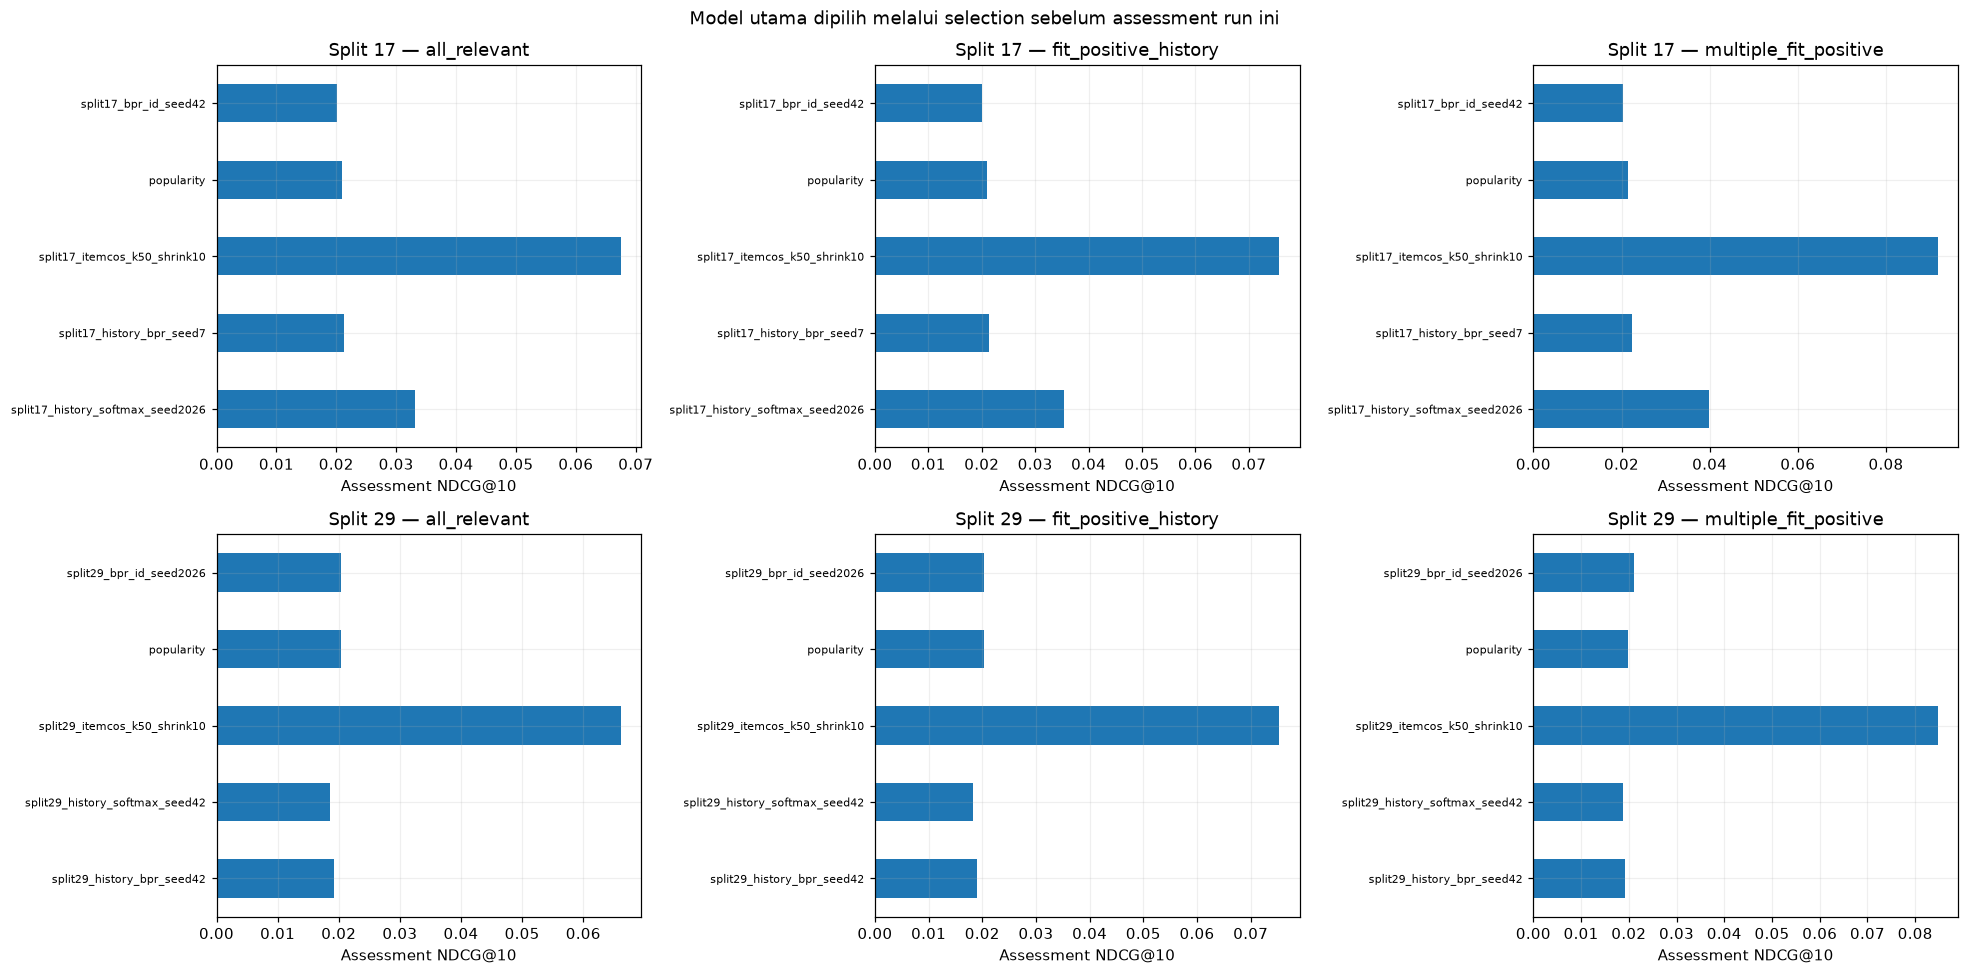

In [11]:
primary_ranking = ranking_table[ranking_table["model utama"]]
fig, axes = plt.subplots(len(split_seeds), 3, figsize=(18, 9), squeeze=False)
for row_index, split_seed in enumerate(split_seeds):
    for column_index, cohort in enumerate(COMPARISON_COHORTS):
        ax = axes[row_index, column_index]
        group = primary_ranking[
            (primary_ranking["split"] == split_seed) & (primary_ranking["cohort"] == cohort)
        ]
        group.set_index("model")["ndcg_at_10"].plot.barh(ax=ax, color="tab:blue")
        ax.set(title=f"Split {split_seed} — {cohort}", xlabel="Assessment NDCG@10", ylabel="")
        ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Model utama dipilih melalui selection sebelum assessment run ini")
plt.tight_layout()
plt.show()

## Diagnosis dengan riwayat pengguna lain

Setelah model utama dipilih dan dikunci, riwayat positif diganti dengan
riwayat donor melalui pemetaan siklik tetap dari pengguna fit yang mempunyai
riwayat positif. Bobot model tetap; ini **bukan training baru**. Karya yang
dikeluarkan dari kandidat tetap karya fit milik penerima rekomendasi. Pengguna
tanpa positif tetap memakai fallback popularitas.

Diagnosis ini memeriksa sensitivitas model terhadap riwayat yang diberikan.
Jika kualitas turun ketika riwayat ditukar, hasil itu mendukung kegunaan
riwayat asli dalam protokol ini. Pertukaran dapat mengubah **isi dan panjang**
riwayat sekaligus; hasilnya bukan identifikasi efek kausal isi buku saja.
Daftar berubah tanpa peningkatan relevansi juga belum membuktikan personalisasi
yang bermanfaat. Penurunan ataupun ketiadaan penurunan perlu dibaca bersama
ukuran cohort dan interval ketidakpastian.

In [12]:
shuffle_metric_rows, shuffle_comparison_rows = [], []
for diagnostic in results["history_shuffle_results"]:
    assert diagnostic["diagnostic_only"] and not diagnostic["used_for_selection"]
    for cohort in COHORTS:
        normal, shuffled = (
            diagnostic[key][cohort] for key in ("normal_metrics", "shuffled_metrics")
        )
        assert normal["users"] == shuffled["users"]
        shuffle_metric_rows.append(
            {
                "split": diagnostic["split_seed"],
                "model": diagnostic["candidate"],
                "cohort": cohort,
                "pengguna": normal["users"],
                "hit riwayat asli": normal["hits_at_10"],
                "hit riwayat donor": shuffled["hits_at_10"],
                "NDCG asli": normal["ndcg_at_10"],
                "NDCG donor": shuffled["ndcg_at_10"],
                "Recall asli": normal["recall_at_10"],
                "Recall donor": shuffled["recall_at_10"],
                "karya unik asli": normal["recommended_unique_works"],
                "karya unik donor": shuffled["recommended_unique_works"],
            }
        )
    for comparison in diagnostic["paired_normal_minus_shuffled"]:
        shuffle_comparison_rows.append(
            {
                "split": diagnostic["split_seed"],
                "model": diagnostic["candidate"],
                "cohort": comparison["cohort"],
                "metrik": comparison["metric"],
                "selisih asli - donor": comparison["difference"],
                "batas bawah 95%": comparison["ci95"][0],
                "batas atas 95%": comparison["ci95"][1],
                "pengguna": comparison["users"],
                "draws": comparison["draws"],
                "seed": comparison["seed"],
            }
        )
shuffle_table = pd.DataFrame(shuffle_metric_rows)
shuffle_bootstrap = pd.DataFrame(shuffle_comparison_rows)
display(shuffle_table)
display(shuffle_bootstrap)
display(
    Markdown("Selisih **asli − donor** positif berarti kualitas lebih baik dengan riwayat asli.")
)

,split,model,cohort,pengguna,hit riwayat asli,hit riwayat donor,NDCG asli,NDCG donor,Recall asli,Recall donor,karya unik asli,karya unik donor
0,17,split17_history_softmax_seed2026,all_relevant,1776,109,48,0.03319073,0.01509632,0.06137387,0.02702703,259,233
1,17,split17_history_softmax_seed2026,fit_positive_history,1513,99,38,0.03540074,0.01416103,0.06543291,0.02511566,259,233
2,17,split17_history_softmax_seed2026,no_fit_positive_history,263,10,10,0.02047690,0.02047690,0.03802281,0.03802281,12,12
3,17,split17_history_softmax_seed2026,single_fit_positive,611,30,17,0.02873694,0.01626876,0.04909984,0.02782324,197,195
4,17,split17_history_softmax_seed2026,multiple_fit_positive,902,69,21,0.03991468,0.01273328,0.07649667,0.02328160,246,224
5,17,split17_history_bpr_seed7,all_relevant,1776,70,63,0.02122022,0.01804331,0.03941441,0.03547297,56,55
6,17,split17_history_bpr_seed7,fit_positive_history,1513,60,53,0.02134943,0.01762029,0.03965631,0.03502974,55,54
7,17,split17_history_bpr_seed7,no_fit_positive_history,263,10,10,0.02047690,0.02047690,0.03802281,0.03802281,12,12
8,17,split17_history_bpr_seed7,single_fit_positive,611,22,20,0.01994965,0.01740125,0.03600655,0.03273322,43,48
9,17,split17_history_bpr_seed7,multiple_fit_positive,902,38,33,0.02229762,0.01776867,0.04212860,0.03658537,50,48


,split,model,cohort,metrik,selisih asli - donor,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_softmax_seed2026,all_relevant,recall_at_10,0.03434685,0.02364865,0.04560811,1776,1000,123
1,17,split17_history_softmax_seed2026,all_relevant,ndcg_at_10,0.01809442,0.01231381,0.02412700,1776,1000,123
2,17,split17_history_softmax_seed2026,all_relevant,mrr_at_10,0.01331220,0.00829980,0.01834587,1776,1000,123
3,17,split17_history_softmax_seed2026,fit_positive_history,recall_at_10,0.04031725,0.02842036,0.05289161,1513,1000,123
4,17,split17_history_softmax_seed2026,fit_positive_history,ndcg_at_10,0.02123971,0.01480044,0.02850904,1513,1000,123
5,17,split17_history_softmax_seed2026,fit_positive_history,mrr_at_10,0.01562621,0.00985172,0.02171474,1513,1000,123
6,17,split17_history_softmax_seed2026,multiple_fit_positive,recall_at_10,0.05321508,0.03658537,0.06987251,902,1000,123
7,17,split17_history_softmax_seed2026,multiple_fit_positive,ndcg_at_10,0.02718140,0.01807429,0.03711066,902,1000,123
8,17,split17_history_softmax_seed2026,multiple_fit_positive,mrr_at_10,0.01950384,0.01166923,0.02789453,902,1000,123
9,17,split17_history_bpr_seed7,all_relevant,recall_at_10,0.00394144,0.00056306,0.00731982,1776,1000,123


Selisih **asli − donor** positif berarti kualitas lebih baik dengan riwayat asli.

## Variasi seed dan ketidakpastian perbandingan

Tiga seed mengukur variasi inisialisasi dan mini-batch pada data yang sama;
mereka bukan tiga dataset independen. Dua split dianalisis terpisah karena
data/pengguna dapat tumpang tindih. Bootstrap meresampling pengguna secara
berpasangan; selisih positif kandidat − referensi menguntungkan kandidat
untuk Recall/NDCG/MRR. Interval bersyarat pada assessment yang dipakai ulang
dan tidak mengoreksi banyak perbandingan.
Interval yang ditetapkan untuk run ini mencakup cohort seluruh pengguna,
riwayat positif, dan minimal dua positif. Cohort tanpa positif dan tepat satu
positif tetap mempunyai metrik lengkap, tetapi tidak ditambah bootstrap
secara post-hoc di notebook.

In [13]:
new_ranking = ranking_table[ranking_table["model"].isin(candidate_by_name)]
seed_summary = (
    new_ranking.groupby(["split", "kelompok", "cohort"], sort=False)
    .agg(
        jumlah_seed=("model", "count"),
        recall_mean=("recall_at_10", "mean"),
        recall_sd=("recall_at_10", "std"),
        ndcg_mean=("ndcg_at_10", "mean"),
        ndcg_sd=("ndcg_at_10", "std"),
        mrr_mean=("mrr_at_10", "mean"),
        mrr_sd=("mrr_at_10", "std"),
    )
    .reset_index()
)
display(seed_summary)
bootstrap_rows = []
for ranking in ranking_results:
    for comparison in ranking["paired_bootstrap"]:
        bootstrap_rows.append(
            {
                "split": ranking["split_seed"],
                "kandidat": comparison["model"],
                "referensi": comparison["reference"],
                "cohort": comparison["cohort"],
                "metrik": comparison["metric"],
                "selisih kandidat - referensi": comparison["difference"],
                "batas bawah 95%": comparison["ci95"][0],
                "batas atas 95%": comparison["ci95"][1],
                "pengguna": comparison["users"],
                "draws": comparison["draws"],
                "seed": comparison["seed"],
            }
        )
bootstrap_table = pd.DataFrame(bootstrap_rows)
for cohort in COMPARISON_COHORTS:
    for metric in ("recall_at_10", "ndcg_at_10", "mrr_at_10"):
        display(Markdown(f"**Semua perbandingan `{metric}` pada `{cohort}`:**"))
        display(
            bootstrap_table[
                (bootstrap_table["cohort"] == cohort) & (bootstrap_table["metrik"] == metric)
            ].reset_index(drop=True)
        )

,split,kelompok,cohort,jumlah_seed,recall_mean,recall_sd,ndcg_mean,ndcg_sd,mrr_mean,mrr_sd
0,17,history_bpr,all_relevant,3,0.03978979,0.00065017,0.02068955,0.00048309,0.01494165,0.00075668
1,17,history_bpr,fit_positive_history,3,0.04009694,0.00076319,0.02072651,0.00056706,0.01489804,0.00088821
2,17,history_bpr,no_fit_positive_history,3,0.03802281,0.00000000,0.02047690,0.00000000,0.01519253,0.00000000
3,17,history_bpr,single_fit_positive,3,0.03818876,0.00250004,0.01981168,0.00019751,0.01424090,0.00079052
4,17,history_bpr,multiple_fit_positive,3,0.04138950,0.00230783,0.02134620,0.00091577,0.01534318,0.00097726
5,17,history_softmax,all_relevant,3,0.05067568,0.01042807,0.02875115,0.00548016,0.02210455,0.00427640
6,17,history_softmax,fit_positive_history,3,0.05287508,0.01224075,0.03018943,0.00643276,0.02330604,0.00501975
7,17,history_softmax,no_fit_positive_history,3,0.03802281,0.00000000,0.02047690,0.00000000,0.01519253,0.00000000
8,17,history_softmax,single_fit_positive,3,0.04528096,0.00411884,0.02618183,0.00272479,0.02029720,0.00232931
9,17,history_softmax,multiple_fit_positive,3,0.05801922,0.01778449,0.03290411,0.00897656,0.02534418,0.00701472


**Semua perbandingan `recall_at_10` pada `all_relevant`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_bpr_seed42,popularity,all_relevant,recall_at_10,-0.00281532,-0.01013514,0.00394144,1776,1000,123
1,17,split17_history_bpr_seed42,split17_bpr_id_seed42,all_relevant,recall_at_10,-0.00112613,-0.00900901,0.00619369,1776,1000,123
2,17,split17_history_bpr_seed42,split17_itemcos_k50_shrink10,all_relevant,recall_at_10,-0.06813063,-0.08445946,-0.05123874,1776,1000,123
3,17,split17_history_bpr_seed42,split17_history_softmax_seed42,all_relevant,recall_at_10,-0.00112613,-0.00675676,0.00450450,1776,1000,123
4,17,split17_history_softmax_seed42,popularity,all_relevant,recall_at_10,-0.00168919,-0.00563063,0.00281532,1776,1000,123
5,17,split17_history_softmax_seed42,split17_bpr_id_seed42,all_relevant,recall_at_10,0.00000000,-0.00675676,0.00675676,1776,1000,123
6,17,split17_history_softmax_seed42,split17_itemcos_k50_shrink10,all_relevant,recall_at_10,-0.06700450,-0.08333333,-0.05123874,1776,1000,123
7,17,split17_history_softmax_seed42,split17_history_bpr_seed42,all_relevant,recall_at_10,0.00112613,-0.00450450,0.00675676,1776,1000,123
8,17,split17_history_bpr_seed2026,popularity,all_relevant,recall_at_10,-0.00168919,-0.00731982,0.00394144,1776,1000,123
9,17,split17_history_bpr_seed2026,split17_bpr_id_seed42,all_relevant,recall_at_10,0.00000000,-0.00675676,0.00619369,1776,1000,123


**Semua perbandingan `ndcg_at_10` pada `all_relevant`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_bpr_seed42,popularity,all_relevant,ndcg_at_10,-0.00069132,-0.00343160,0.00197321,1776,1000,123
1,17,split17_history_bpr_seed42,split17_bpr_id_seed42,all_relevant,ndcg_at_10,0.00018748,-0.00285694,0.00342975,1776,1000,123
2,17,split17_history_bpr_seed42,split17_itemcos_k50_shrink10,all_relevant,ndcg_at_10,-0.04724664,-0.05821005,-0.03664032,1776,1000,123
3,17,split17_history_bpr_seed42,split17_history_softmax_seed42,all_relevant,ndcg_at_10,-0.00235093,-0.00510320,0.00042510,1776,1000,123
4,17,split17_history_softmax_seed42,popularity,all_relevant,ndcg_at_10,0.00165961,-0.00075323,0.00463441,1776,1000,123
5,17,split17_history_softmax_seed42,split17_bpr_id_seed42,all_relevant,ndcg_at_10,0.00253842,-0.00057471,0.00602075,1776,1000,123
6,17,split17_history_softmax_seed42,split17_itemcos_k50_shrink10,all_relevant,ndcg_at_10,-0.04489571,-0.05577471,-0.03428107,1776,1000,123
7,17,split17_history_softmax_seed42,split17_history_bpr_seed42,all_relevant,ndcg_at_10,0.00235093,-0.00042510,0.00510320,1776,1000,123
8,17,split17_history_bpr_seed2026,popularity,all_relevant,ndcg_at_10,-0.00039356,-0.00360315,0.00299153,1776,1000,123
9,17,split17_history_bpr_seed2026,split17_bpr_id_seed42,all_relevant,ndcg_at_10,0.00048524,-0.00331412,0.00410171,1776,1000,123


...

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_bpr_seed42,popularity,multiple_fit_positive,recall_at_10,-0.00665188,-0.01773836,0.00446231,902,1000,123
1,17,split17_history_bpr_seed42,split17_bpr_id_seed42,multiple_fit_positive,recall_at_10,-0.00221729,-0.01441242,0.00997783,902,1000,123
2,17,split17_history_bpr_seed42,split17_itemcos_k50_shrink10,multiple_fit_positive,recall_at_10,-0.10643016,-0.13192905,-0.08314856,902,1000,123
3,17,split17_history_bpr_seed42,split17_history_softmax_seed42,multiple_fit_positive,recall_at_10,-0.00221729,-0.01108647,0.00776053,902,1000,123
4,17,split17_history_softmax_seed42,popularity,multiple_fit_positive,recall_at_10,-0.00443459,-0.01219512,0.00221729,902,1000,123
5,17,split17_history_softmax_seed42,split17_bpr_id_seed42,multiple_fit_positive,recall_at_10,0.00000000,-0.01108647,0.00997783,902,1000,123
6,17,split17_history_softmax_seed42,split17_itemcos_k50_shrink10,multiple_fit_positive,recall_at_10,-0.10421286,-0.12638581,-0.08093126,902,1000,123
7,17,split17_history_softmax_seed42,split17_history_bpr_seed42,multiple_fit_positive,recall_at_10,0.00221729,-0.00776053,0.01108647,902,1000,123
8,17,split17_history_bpr_seed2026,popularity,multiple_fit_positive,recall_at_10,-0.00221729,-0.01108647,0.00665188,902,1000,123
9,17,split17_history_bpr_seed2026,split17_bpr_id_seed42,multiple_fit_positive,recall_at_10,0.00221729,-0.00886918,0.01330377,902,1000,123


**Semua perbandingan `ndcg_at_10` pada `multiple_fit_positive`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_bpr_seed42,popularity,multiple_fit_positive,ndcg_at_10,-0.00098079,-0.00523552,0.00341023,902,1000,123
1,17,split17_history_bpr_seed42,split17_bpr_id_seed42,multiple_fit_positive,ndcg_at_10,0.00024030,-0.00480762,0.00557273,902,1000,123
2,17,split17_history_bpr_seed42,split17_itemcos_k50_shrink10,multiple_fit_positive,ndcg_at_10,-0.07127254,-0.08695503,-0.05546908,902,1000,123
3,17,split17_history_bpr_seed42,split17_history_softmax_seed42,multiple_fit_positive,ndcg_at_10,-0.00231608,-0.00629133,0.00193767,902,1000,123
4,17,split17_history_softmax_seed42,popularity,multiple_fit_positive,ndcg_at_10,0.00133529,-0.00262460,0.00596462,902,1000,123
5,17,split17_history_softmax_seed42,split17_bpr_id_seed42,multiple_fit_positive,ndcg_at_10,0.00255638,-0.00284970,0.00790666,902,1000,123
6,17,split17_history_softmax_seed42,split17_itemcos_k50_shrink10,multiple_fit_positive,ndcg_at_10,-0.06895646,-0.08412793,-0.05320708,902,1000,123
7,17,split17_history_softmax_seed42,split17_history_bpr_seed42,multiple_fit_positive,ndcg_at_10,0.00231608,-0.00193767,0.00629133,902,1000,123
8,17,split17_history_bpr_seed2026,popularity,multiple_fit_positive,ndcg_at_10,-0.00018146,-0.00530942,0.00521360,902,1000,123
9,17,split17_history_bpr_seed2026,split17_bpr_id_seed42,multiple_fit_positive,ndcg_at_10,0.00103963,-0.00527043,0.00741849,902,1000,123


**Semua perbandingan `mrr_at_10` pada `multiple_fit_positive`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_bpr_seed42,popularity,multiple_fit_positive,mrr_at_10,0.00055872,-0.00213698,0.00339814,902,1000,123
1,17,split17_history_bpr_seed42,split17_bpr_id_seed42,multiple_fit_positive,mrr_at_10,0.00091903,-0.00245154,0.00467666,902,1000,123
2,17,split17_history_bpr_seed42,split17_itemcos_k50_shrink10,multiple_fit_positive,mrr_at_10,-0.06001082,-0.07495351,-0.04551908,902,1000,123
3,17,split17_history_bpr_seed42,split17_history_softmax_seed42,multiple_fit_positive,mrr_at_10,-0.00233564,-0.00615883,0.00118861,902,1000,123
4,17,split17_history_softmax_seed42,popularity,multiple_fit_positive,mrr_at_10,0.00289436,-0.00052749,0.00730986,902,1000,123
5,17,split17_history_softmax_seed42,split17_bpr_id_seed42,multiple_fit_positive,mrr_at_10,0.00325467,-0.00080627,0.00786359,902,1000,123
6,17,split17_history_softmax_seed42,split17_itemcos_k50_shrink10,multiple_fit_positive,mrr_at_10,-0.05767518,-0.07221497,-0.04331873,902,1000,123
7,17,split17_history_softmax_seed42,split17_history_bpr_seed42,multiple_fit_positive,mrr_at_10,0.00233564,-0.00118861,0.00615883,902,1000,123
8,17,split17_history_bpr_seed2026,popularity,multiple_fit_positive,mrr_at_10,0.00029388,-0.00519490,0.00563612,902,1000,123
9,17,split17_history_bpr_seed2026,split17_bpr_id_seed42,multiple_fit_positive,mrr_at_10,0.00065419,-0.00505232,0.00620474,902,1000,123


## Keputusan yang dapat diambil dari hasil ini

Peningkatan terhadap BPR ID lama, terhadap pembanding cosine riwayat, dan
terhadap popularitas menjawab pertanyaan berbeda. Pertukaran riwayat membantu
menguji ketergantungan masukan, bukan menggantikan evaluasi relevansi. Klaim
umum tetap membutuhkan data konfirmasi yang tidak dipakai menyetel rancangan.
Tidak ada model yang otomatis dipromosikan ke aplikasi berdasarkan assessment
pengembangan ini.

**Kesimpulan run ini:** memakai riwayat adalah arah yang layak, dan pembanding
cosine menunjukkan hasil yang lebih kuat pada dua split pengembangan. Neural
softmax berhasil memperbaiki satu split tetapi tidak mengulang keberhasilan
itu pada split lainnya. Menambahkan arsitektur history saja belum cukup untuk
menyatakan neural unggul. Tidak ada dasar untuk menyalahkan data secara
keseluruhan atau menganggap tambahan epoch pasti menyelesaikan masalah;
variasi seed, pemilihan checkpoint, cohort, dan pembanding tetap perlu dinilai.

In [14]:
for ranking in ranking_results:
    display(Markdown(f"**Split {ranking['split_seed']} — NDCG model utama pada riwayat positif:**"))
    comparisons = bootstrap_table[
        (bootstrap_table["split"] == ranking["split_seed"])
        & (bootstrap_table["cohort"] == "fit_positive_history")
        & (bootstrap_table["metrik"] == "ndcg_at_10")
    ]
    display(
        comparisons[
            comparisons["kandidat"].isin(ranking["primary_models"].values())
            & comparisons["referensi"].isin(
                [
                    "popularity",
                    ranking["baseline_name"],
                    ranking["previous_primary_models"]["bpr_id"],
                ]
            )
        ].reset_index(drop=True)
    )
    paired = comparisons[
        comparisons["kandidat"].str.startswith(f"split{ranking['split_seed']}_history_softmax_seed")
        & comparisons["referensi"].str.startswith(f"split{ranking['split_seed']}_history_bpr_seed")
    ]
    assert len(paired) == len(training_seeds)
    display(
        Markdown(
            f"Pada pasangan seed yang sama, softmax memiliki NDCG lebih tinggi dari BPR pada "
            f"**{int((paired['selisih kandidat - referensi'] > 0).sum())}/{len(paired)}** pasangan. "
            f"**{int((paired['batas bawah 95%'] > 0).sum())}** interval berada seluruhnya di atas nol; "
            f"**{int((paired['batas atas 95%'] < 0).sum())}** seluruhnya di bawah nol. "
            "Ini ringkasan deskriptif interval bersyarat, bukan replikasi dataset independen."
        )
    )
    display(paired.reset_index(drop=True))
display(
    Markdown(
        f"Run ini mencatat **{len(candidates)} training neural**, **{len(baselines)} konfigurasi "
        f"klasik**, dan **{len(epochs)} epoch neural**. "
        f"**{len(results['history_shuffle_results'])}** evaluasi pertukaran riwayat tidak "
        "menambah jumlah training. Diagnosis personalisasi dari run terdahulu juga "
        "analisis bukti tersimpan, bukan model yang dilatih ulang."
    )
)

**Split 17 — NDCG model utama pada riwayat positif:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_softmax_seed2026,popularity,fit_positive_history,ndcg_at_10,0.01434896,0.00848076,0.02011540,1513,1000,123
1,17,split17_history_softmax_seed2026,split17_bpr_id_seed42,fit_positive_history,ndcg_at_10,0.01538052,0.00948085,0.02180497,1513,1000,123
2,17,split17_history_softmax_seed2026,split17_itemcos_k50_shrink10,fit_positive_history,ndcg_at_10,-0.04029893,-0.05197590,-0.02905892,1513,1000,123
3,17,split17_history_bpr_seed7,popularity,fit_positive_history,ndcg_at_10,0.00029765,-0.00355637,0.00408386,1513,1000,123
4,17,split17_history_bpr_seed7,split17_bpr_id_seed42,fit_positive_history,ndcg_at_10,0.00132921,-0.00282706,0.00579566,1513,1000,123
5,17,split17_history_bpr_seed7,split17_itemcos_k50_shrink10,fit_positive_history,ndcg_at_10,-0.05435023,-0.06657548,-0.04131438,1513,1000,123


Pada pasangan seed yang sama, softmax memiliki NDCG lebih tinggi dari BPR pada **3/3** pasangan. **2** interval berada seluruhnya di atas nol; **0** seluruhnya di bawah nol. Ini ringkasan deskriptif interval bersyarat, bukan replikasi dataset independen.

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,17,split17_history_softmax_seed42,split17_history_bpr_seed42,fit_positive_history,ndcg_at_10,0.00275959,-0.00046351,0.00594345,1513,1000,123
1,17,split17_history_softmax_seed2026,split17_history_bpr_seed2026,fit_positive_history,ndcg_at_10,0.01481093,0.00871894,0.02153138,1513,1000,123
2,17,split17_history_softmax_seed7,split17_history_bpr_seed7,fit_positive_history,ndcg_at_10,0.01081825,0.00444262,0.01706519,1513,1000,123


**Split 29 — NDCG model utama pada riwayat positif:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,29,split29_history_bpr_seed42,popularity,fit_positive_history,ndcg_at_10,-0.00126392,-0.00548774,0.00248624,1502,1000,123
1,29,split29_history_bpr_seed42,split29_bpr_id_seed2026,fit_positive_history,ndcg_at_10,-0.00138855,-0.00566762,0.00282532,1502,1000,123
2,29,split29_history_bpr_seed42,split29_itemcos_k50_shrink10,fit_positive_history,ndcg_at_10,-0.05636493,-0.06745969,-0.04579319,1502,1000,123
3,29,split29_history_softmax_seed42,popularity,fit_positive_history,ndcg_at_10,-0.00205120,-0.00379700,-0.00034459,1502,1000,123
4,29,split29_history_softmax_seed42,split29_bpr_id_seed2026,fit_positive_history,ndcg_at_10,-0.00217583,-0.00443549,0.00027315,1502,1000,123
5,29,split29_history_softmax_seed42,split29_itemcos_k50_shrink10,fit_positive_history,ndcg_at_10,-0.05715221,-0.06863716,-0.04554674,1502,1000,123


Pada pasangan seed yang sama, softmax memiliki NDCG lebih tinggi dari BPR pada **2/3** pasangan. **0** interval berada seluruhnya di atas nol; **0** seluruhnya di bawah nol. Ini ringkasan deskriptif interval bersyarat, bukan replikasi dataset independen.

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,draws,seed
0,29,split29_history_softmax_seed42,split29_history_bpr_seed42,fit_positive_history,ndcg_at_10,-0.00078728,-0.00468535,0.00310186,1502,1000,123
1,29,split29_history_softmax_seed2026,split29_history_bpr_seed2026,fit_positive_history,ndcg_at_10,0.00142148,-0.00160496,0.00435625,1502,1000,123
2,29,split29_history_softmax_seed7,split29_history_bpr_seed7,fit_positive_history,ndcg_at_10,0.00080297,-0.00264153,0.00382481,1502,1000,123


Run ini mencatat **12 training neural**, **8 konfigurasi klasik**, dan **136 epoch neural**. **4** evaluasi pertukaran riwayat tidak menambah jumlah training. Diagnosis personalisasi dari run terdahulu juga analisis bukti tersimpan, bukan model yang dilatih ulang.

## Penyimpanan bukti dan reproduksi

Notebook membaca JSON di repository, sedangkan model, state optimizer/RNG,
log, serta rekomendasi rinci disimpan di workspace lokal. Manifest mencatat
verifikasi hash, pengujian perangkat lunak, dan pemeriksaan akhir sesi Colab.
Status runtime adalah catatan audit tersimpan, bukan pemeriksaan langsung
ketika notebook dibuka kembali.

Untuk memeriksa notebook, jalankan `scripts/notebook_quality.py check-pair`
pada pasangan `.ipynb`/`.py` dan `check-saved` dengan tiga JSON pada
`EVIDENCE_FILES` sebagai `--dependency`. Restart & Run All hanya membaca bukti;
ia tidak menjalankan kembali eksperimen atau membuka assessment baru.

In [15]:
display(
    pd.DataFrame(
        [
            {"catatan": "Sesi khusus proyek", "nilai": manifest["session_name"]},
            {
                "catatan": "Akun Free dikonfirmasi",
                "nilai": manifest["account_free_without_paid_balance_confirmed_by_user"],
            },
            {
                "catatan": "Sumber daya berbayar diizinkan",
                "nilai": manifest["paid_resources_authorized"],
            },
            {"catatan": "Tes perangkat lunak lulus", "nilai": manifest["runtime_tests"]["passed"]},
            {"catatan": "Arsip terverifikasi", "nilai": len(manifest["backups"])},
        ]
    )
)
display(pd.DataFrame(manifest["backups"]))
display(
    pd.DataFrame(
        [{"catatan akhir sesi": key, "nilai": value} for key, value in manifest["shutdown"].items()]
    )
)
display(pd.DataFrame({"batas interpretasi dari hasil run": results["limitations"]}))
assert not manifest["paid_resources_authorized"]
assert manifest["verification"]["all_backups_verified"]

,catatan,nilai
0,Sesi khusus proyek,book-recommendation-neural-20261014-history
1,Akun Free dikonfirmasi,True
2,Sumber daya berbayar diizinkan,False
3,Tes perangkat lunak lulus,18
4,Arsip terverifikasi,42


,archive,sha256,bytes,kind,epoch,members,verified_utc
0,inputs_backup.tar.gz,fa435b329bc732dc8625b1bbdd54e1d9328a82c1d42dc6fb0baf05aeb159f5c9,16206297,training_inputs,NaN,35,2026-10-14T09:57:42.283385+00:00
1,epoch_001_snapshot.tar.gz,0950e44af477c5d4923aeb0a1c49e813150c0e361146f92d34a87a3170383c56,16994226,epoch_checkpoint,0.0,54,2026-10-14T09:58:20.782400+00:00
2,epoch_002_snapshot.tar.gz,5107bb2fd779b532386d9acc1db22dd8de080d5996aa572a74900a1c06eabea9,4599485,epoch_checkpoint,5.0,10,2026-10-14T09:58:27.657747+00:00
3,epoch_003_snapshot.tar.gz,0f7328ebafa351b08baf1a5dfa87e09d5ac8a5cefdb0e21775a39a5016212623,4606784,epoch_checkpoint,10.0,10,2026-10-14T09:58:59.326497+00:00
4,epoch_004_snapshot.tar.gz,bb7da5103f8a37606f6a39b0cf53736feddf7986e0c84f4cd189315ba0612704,7330846,epoch_checkpoint,10.0,18,2026-10-14T09:59:06.774975+00:00
5,epoch_005_snapshot.tar.gz,b7b7ae9f8d45dd61d7d3ee13f8f2f200023e4db40fc61242e34cf4f15b485dc4,4608201,epoch_checkpoint,15.0,10,2026-10-14T09:59:11.701442+00:00
6,epoch_006_snapshot.tar.gz,2ac0e51a110e9d0f143f1dfc75360faa0847e055f9698c5879ccebf99644a4ac,7330495,epoch_checkpoint,18.0,18,2026-10-14T09:59:20.870717+00:00
7,epoch_007_snapshot.tar.gz,5a08d51753c5815be958129a903dc27ccc529a69ea61aef9aabb0ecbc376407d,4606517,epoch_checkpoint,23.0,10,2026-10-14T09:59:55.819950+00:00
8,epoch_008_snapshot.tar.gz,7d856a95e42538a49a4d78831424c09fc3ba5fd11da2bd376c45fe2d458f64d2,7321950,epoch_checkpoint,25.0,18,2026-10-14T10:00:04.275374+00:00
9,epoch_009_snapshot.tar.gz,f497251e13c3850054e4863994f86fe8d151a66970d3852a73977c9bf15b1045,4619449,epoch_checkpoint,30.0,10,2026-10-14T10:00:10.070158+00:00


,catatan akhir sesi,nilai
0,stopped,True
1,after_backup_and_result_verification,True
2,stop_attempt_after_backup_and_result_verification,True
3,inactive_state_verified_after_backup_and_result_verification,True
4,stop_operation,artifacts/colab/operations/history-stop-owned-session-20261014T101431-afe8dc02.json
5,server_check_operation,artifacts/colab/operations/history-verify-server-stopped-20261014T101441-774954e8.json
6,server_reports_no_active_sessions,True
7,completed_at_utc,2026-10-14T10:14:43.848544+00:00
8,stop_command_succeeded,True
9,stop_returned_not_found,False


,batas interpretasi dari hasil run
0,Repeatedly inspected internal development assessment is not an independent confirmation set.
1,"BPR and full softmax share context, architecture, eligible target examples and initialization, but differ ..."
2,Only users with two or more fit-positive works supply training examples; inference can use one positive wo...
3,History is an unordered set with no timestamps or sequence claim; high-activity users contribute more targ...
4,All unobserved works are unknown preferences; masking observed works does not create true negative labels.
5,"The new cosine control uses binary positive work co-occurrence, not the application's adjusted-cosine ISBN..."
6,Cosine ties use fit popularity; neural ties use lexical work order. All models share no-positive-user popu...
7,Fixed history shuffling is a diagnostic perturbation; recipients retain their own exclusions and it is not...
8,"Three seeds per split, overlapping split users, unadjusted conditional bootstrap; do not pool split observ..."
9,A best checkpoint at the epoch cap does not establish convergence; no model is automatically promoted to t...
